# Cybersecurity Threat Severity and Impact Classification
## Proyecto de Aula — Modelos y Simulación de Sistemas II
**Departamento de Ingeniería de Sistemas — Universidad de Antioquia**  
**Autores:** Luis Carlos Vanegas Zapata, Alejandra Cano Espinosa, Robinson Dario Henao Botero  

---

### Índice General del Proyecto

- **Sección 0: Contexto del problema y mapa de cumplimiento del Entregable II**

- **Parte I: Análisis Exploratorio de Datos (EDA)**
  1. Carga de librerías y del dataset
  2. Inspección general (dimensiones, tipos, valores nulos, duplicados)
  3. Estadística descriptiva de variables numéricas
  4. Distribución de variables numéricas
  5. Distribución de variables categóricas
  6. Relaciones entre variables (correlación lineal y diagramas de caja)
  7. Construcción de la variable objetivo de severidad (terciles) y diagnóstico de balance
  8. Imputación de datos faltantes
  9. Codificación de variables (One-Hot + Z-score) y partición de datos (Holdout 80/20)
  10. Conclusiones del EDA

- **Parte II: Entrenamiento, Evaluación de Modelos y Reducción de Dimensión**
  - **Sección 1: Entrenamiento y Evaluación (30%)**
    - 1.1 Configuración Experimental
      - 1.1.A Metodología de validación y gestión del balance de clases
      - 1.1.B Malla de hiperparámetros y definición unificada de modelos
      - 1.1.C Métricas de desempeño y justificación
    - 1.2 Resultados Experimentales
      - Efecto de los hiperparámetros en el desempeño (Figura 1)
      - Tabla comparativa de resultados con intervalos de confianza (Tabla 2)
      - Ranking de modelos por validación y selección de los dos mejores clasificadores
      - Matrices de confusión y distribución de predicciones en prueba (Figura 2)
      - Experimento de sensibilidad a las estrategias de balance (Tabla 3 y Figura 3)
      - Análisis crítico de resultados
  - **Sección 2: Reducción de Dimensión (20%)**
    - 2.1 Análisis individual de cada característica: ANOVA $F$ e Información Mutua (Tabla 4 y Figura 4)
    - 2.2 Extracción lineal de características: PCA con criterio $\ge 90\%$ de varianza (Figura 5 y Tabla 5)
    - 2.3.A Extracción no lineal de características: UMAP y selección de componentes latentes (Figura 6 y Tabla 6)
    - 2.3.B Discusión y conclusiones de la evaluación completa (Figura 7 y Tabla 7)

## 0. Contexto del problema y mapa de cumplimiento del Entregable II

**Problema.** Triaje automático de incidentes de ciberseguridad: dado un incidente en el momento de su detección ($t=0$), predecir su nivel de severidad $Y \in \{\text{Low}, \text{Medium}, \text{High}\}$ para priorizar la respuesta.

**Datos.** Dataset público *Global Cybersecurity Threats 2015-2024* (Kaggle): 3.000 incidentes y 10 variables (país, año, tipo de ataque, sector afectado, usuarios afectados, fuente del ataque, tipo de vulnerabilidad, mecanismo de defensa, pérdida financiera y tiempo de resolución).

**Variable objetivo.** La severidad se construye discretizando por terciles un índice de impacto combinado (promedio de los rangos percentiles de la pérdida financiera y del tiempo de resolución).

**Restricción anti-fuga.** Las variables que definen la severidad (`Financial Loss`, `Incident Resolution Time`) y el índice `Impact_Score` se excluyen del espacio de características; solo se usan las 8 variables disponibles en $t=0$.

**Paradigma.** Aprendizaje supervisado, clasificación multiclase (3 clases).

**Mapa de cumplimiento del Entregable II.**

| Requisito | Dónde se cubre en este notebook |
|---|---|
| Entregable I incorporado (con mejoras) | Sección 0 y Parte I (EDA, secciones 1 a 10) |
| 1.1.A Metodología de validación y gestión del balance de clases | Sección 1.1.A, diagnóstico de balance, Tabla 3 y prueba de estrés (Tabla 3B, Figura 3B) |
| 1.1.B Tabla de hiperparámetros (5 familias de modelos) | Sección 1.1.B, Tabla 1 |
| 1.1.C Métricas de desempeño y justificación | Sección 1.1.C |
| 1.2 Resultados de entrenamiento, validación y prueba con IC | Sección 1.2: Figura 1, Tabla 2, Figura 2, Tabla 3, Figura 3 y análisis crítico |
| 2.1 Análisis individual de variables y candidatas a eliminar | Sección 2.1, Tabla 4, Figura 4 |
| 2.2 Extracción lineal (PCA) | Sección 2.2, Figura 5, Tabla 5 |
| 2.3.A Extracción no lineal (UMAP) | Sección 2.3.A, Figura 6, Tabla 6 |
| 2.3.B Discusión y conclusiones | Sección 2.3.B, Figura 7, Tabla 7 y conclusiones finales |


## 1. Carga de librerías y del dataset

In [1]:
!pip -q install imbalanced-learn umap-learn kagglehub

import os
import glob
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["figure.dpi"] = 100

# --------------------------------------------------------------------
# Carga del dataset: primero se intenta con kagglehub (descarga automática);
# si no está instalado o falla, se usa una ruta local manual como respaldo.
# --------------------------------------------------------------------

# Opción A: ruta local
MANUAL_DATA_PATH = "data/Global_Cybersecurity_Threats_2015-2024.csv"

df = None

try:
    import kagglehub

    dataset_dir = kagglehub.dataset_download(
        "atharvasoundankar/global-cybersecurity-threats-2015-2024"
    )
    print("Dataset descargado por kagglehub en:", dataset_dir)

    csv_files = glob.glob(os.path.join(dataset_dir, "*.csv"))
    if csv_files:
        DATA_PATH = csv_files[0]
        print("Archivo CSV encontrado:", DATA_PATH)
        df = pd.read_csv(DATA_PATH)
    else:
        print("kagglehub descargó la carpeta pero no se encontró ningún .csv dentro.")
except ModuleNotFoundError:
    print("kagglehub no está instalado (pip install kagglehub). Se usará la ruta manual.")
except Exception as e:
    print(f"No se pudo descargar con kagglehub ({e}). Se usará la ruta manual.")

if df is None:
    if os.path.exists(MANUAL_DATA_PATH):
        print("Cargando dataset desde ruta manual:", MANUAL_DATA_PATH)
        df = pd.read_csv(MANUAL_DATA_PATH)
    else:
        raise FileNotFoundError(
            "No se encontró el dataset. Opciones:\n"
            "  1) Instala kagglehub ('pip install kagglehub') y vuelve a correr esta celda, o\n"
            f"  2) Descarga el CSV manualmente desde Kaggle y colócalo en: {MANUAL_DATA_PATH}\n"
            "     (crea la carpeta 'data/' junto a este notebook si no existe)."
        )

print(f"\nDimensiones del dataset: {df.shape}")
df.head()

Using Colab cache for faster access to the 'global-cybersecurity-threats-2015-2024' dataset.
Dataset descargado por kagglehub en: /kaggle/input/global-cybersecurity-threats-2015-2024
Archivo CSV encontrado: /kaggle/input/global-cybersecurity-threats-2015-2024/Global_Cybersecurity_Threats_2015-2024.csv

Dimensiones del dataset: (3000, 10)


,Country,Year,Attack Type,Target Industry,Financial Loss (in Million $),Number of Affected Users,Attack Source,Security Vulnerability Type,Defense Mechanism Used,Incident Resolution Time (in Hours)
0,China,2019,Phishing,Education,80.53,773169,Hacker Group,Unpatched Software,VPN,63
1,China,2019,Ransomware,Retail,62.19,295961,Hacker Group,Unpatched Software,Firewall,71
2,India,2017,Man-in-the-Middle,IT,38.65,605895,Hacker Group,Weak Passwords,VPN,20
3,UK,2024,Ransomware,Telecommunications,41.44,659320,Nation-state,Social Engineering,AI-based Detection,7
4,Germany,2018,Man-in-the-Middle,IT,74.41,810682,Insider,Social Engineering,VPN,68


## 2. Inspección general

Verificamos dimensiones, tipos de dato, nombres de columnas, duplicados y valores nulos,
como parte de la caracterización del dataset descrita en la Sección 0 de este notebook.

In [2]:
print(f"Número de muestras (N): {df.shape[0]}")
print(f"Número de variables (D): {df.shape[1]}")
print()
df.info()


Número de muestras (N): 3000
Número de variables (D): 10

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 10 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Country                              3000 non-null   object 
 1   Year                                 3000 non-null   int64  
 2   Attack Type                          3000 non-null   object 
 3   Target Industry                      3000 non-null   object 
 4   Financial Loss (in Million $)        3000 non-null   float64
 5   Number of Affected Users             3000 non-null   int64  
 6   Attack Source                        3000 non-null   object 
 7   Security Vulnerability Type          3000 non-null   object 
 8   Defense Mechanism Used               3000 non-null   object 
 9   Incident Resolution Time (in Hours)  3000 non-null   int64  
dtypes: float64(1), int64(3), object(6)
mem

In [3]:
# Normalizar nombres de columnas por si vienen con espacios/paréntesis distintos
df.columns = [c.strip() for c in df.columns]
print(df.columns.tolist())


['Country', 'Year', 'Attack Type', 'Target Industry', 'Financial Loss (in Million $)', 'Number of Affected Users', 'Attack Source', 'Security Vulnerability Type', 'Defense Mechanism Used', 'Incident Resolution Time (in Hours)']


In [4]:
# Duplicados
n_dup = df.duplicated().sum()
print(f"Filas duplicadas: {n_dup}")

# Valores nulos por columna
nulos = df.isnull().sum().sort_values(ascending=False)
pct_nulos = (nulos / len(df) * 100).round(2)
resumen_nulos = pd.DataFrame({"nulos": nulos, "% nulos": pct_nulos})
resumen_nulos


Filas duplicadas: 0


,nulos,% nulos
Country,0,0.0
Year,0,0.0
Attack Type,0,0.0
Target Industry,0,0.0
Financial Loss (in Million $),0,0.0
Number of Affected Users,0,0.0
Attack Source,0,0.0
Security Vulnerability Type,0,0.0
Defense Mechanism Used,0,0.0
Incident Resolution Time (in Hours),0,0.0


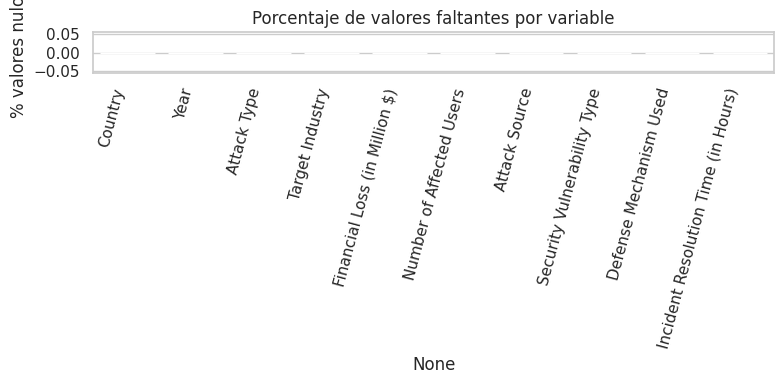

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=resumen_nulos.index, y=resumen_nulos["% nulos"], ax=ax, color="#4C72B0")
ax.set_ylabel("% valores nulos")
ax.set_title("Porcentaje de valores faltantes por variable")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()


## 3. Estadística descriptiva de variables numéricas

Variables cuantitativas: `Financial Loss (in Million $)`, `Number of Affected Users`,
`Incident Resolution Time (in Hours)` y `Year`.

In [6]:
num_cols = [
    "Financial Loss (in Million $)",
    "Number of Affected Users",
    "Incident Resolution Time (in Hours)",
    "Year",
]
num_cols = [c for c in num_cols if c in df.columns]
df[num_cols].describe().T


,count,mean,std,min,25%,50%,75%,max
Financial Loss (in Million $),3000.0,50.492970,28.791415,0.5,25.7575,50.795,75.63,99.99
Number of Affected Users,3000.0,504684.136333,289944.084972,424.0,255805.2500,504513.000,758088.50,999635.00
Incident Resolution Time (in Hours),3000.0,36.476000,20.570768,1.0,19.0000,37.000,55.00,72.00
Year,3000.0,2019.570333,2.857932,2015.0,2017.0000,2020.000,2022.00,2024.00


## 4. Distribución de variables numéricas

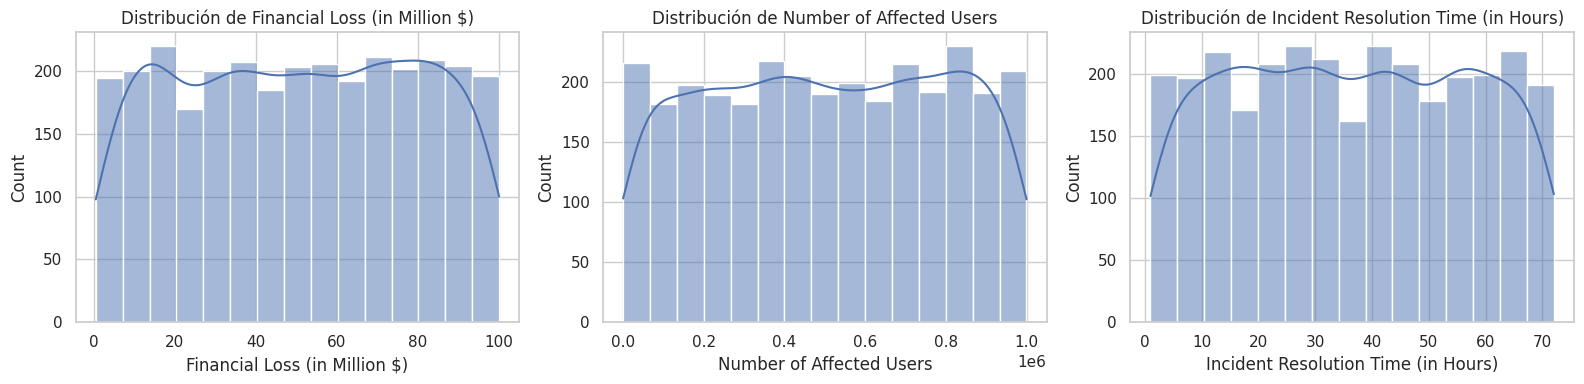

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
dist_cols = [c for c in num_cols if c != "Year"]
for ax, col in zip(axes, dist_cols):
    sns.histplot(df[col], kde=True, ax=ax, color="#4C72B0")
    ax.set_title(f"Distribución de {col}")
plt.tight_layout()
plt.show()


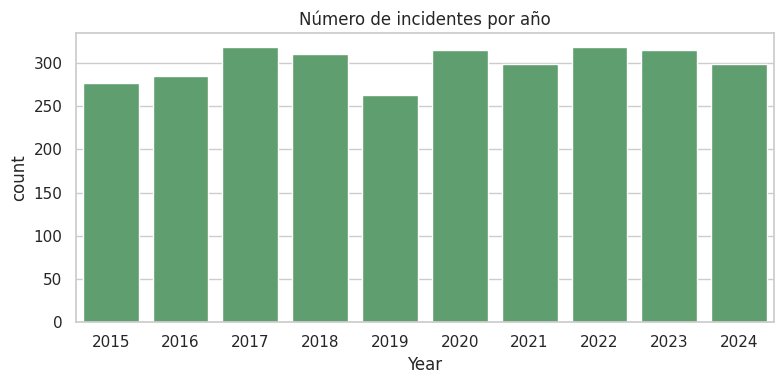

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.countplot(x="Year", data=df, color="#55A868", ax=ax)
ax.set_title("Número de incidentes por año")
plt.tight_layout()
plt.show()


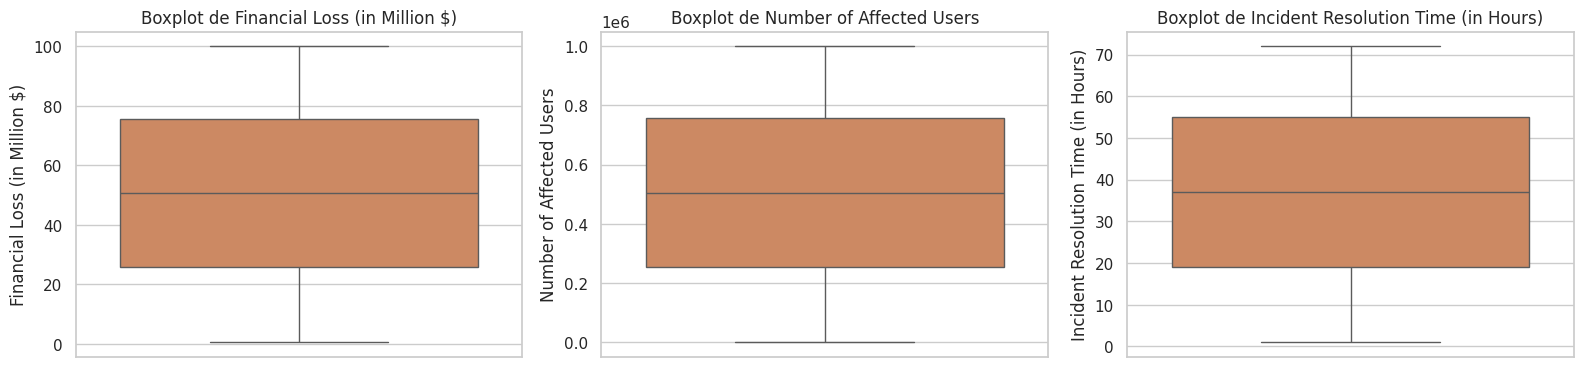

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, dist_cols):
    sns.boxplot(y=df[col], ax=ax, color="#DD8452")
    ax.set_title(f"Boxplot de {col}")
plt.tight_layout()
plt.show()


## 5. Distribución de variables categóricas

Variables: `Country`, `Attack Type`, `Target Industry`, `Attack Source`,
`Security Vulnerability Type`, `Defense Mechanism Used`.

In [10]:
cat_cols = [
    "Country",
    "Attack Type",
    "Target Industry",
    "Attack Source",
    "Security Vulnerability Type",
    "Defense Mechanism Used",
]
cat_cols = [c for c in cat_cols if c in df.columns]

for col in cat_cols:
    print(f"--- {col} ---")
    print(df[col].value_counts())
    print()


--- Country ---
Country
UK           321
Brazil       310
India        308
Japan        305
France       305
Australia    297
Russia       295
Germany      291
USA          287
China        281
Name: count, dtype: int64

--- Attack Type ---
Attack Type
DDoS                 531
Phishing             529
SQL Injection        503
Ransomware           493
Malware              485
Man-in-the-Middle    459
Name: count, dtype: int64

--- Target Industry ---
Target Industry
IT                    478
Banking               445
Healthcare            429
Retail                423
Education             419
Government            403
Telecommunications    403
Name: count, dtype: int64

--- Attack Source ---
Attack Source
Nation-state    794
Unknown         768
Insider         752
Hacker Group    686
Name: count, dtype: int64

--- Security Vulnerability Type ---
Security Vulnerability Type
Zero-day              785
Social Engineering    747
Unpatched Software    738
Weak Passwords        730
Name: coun

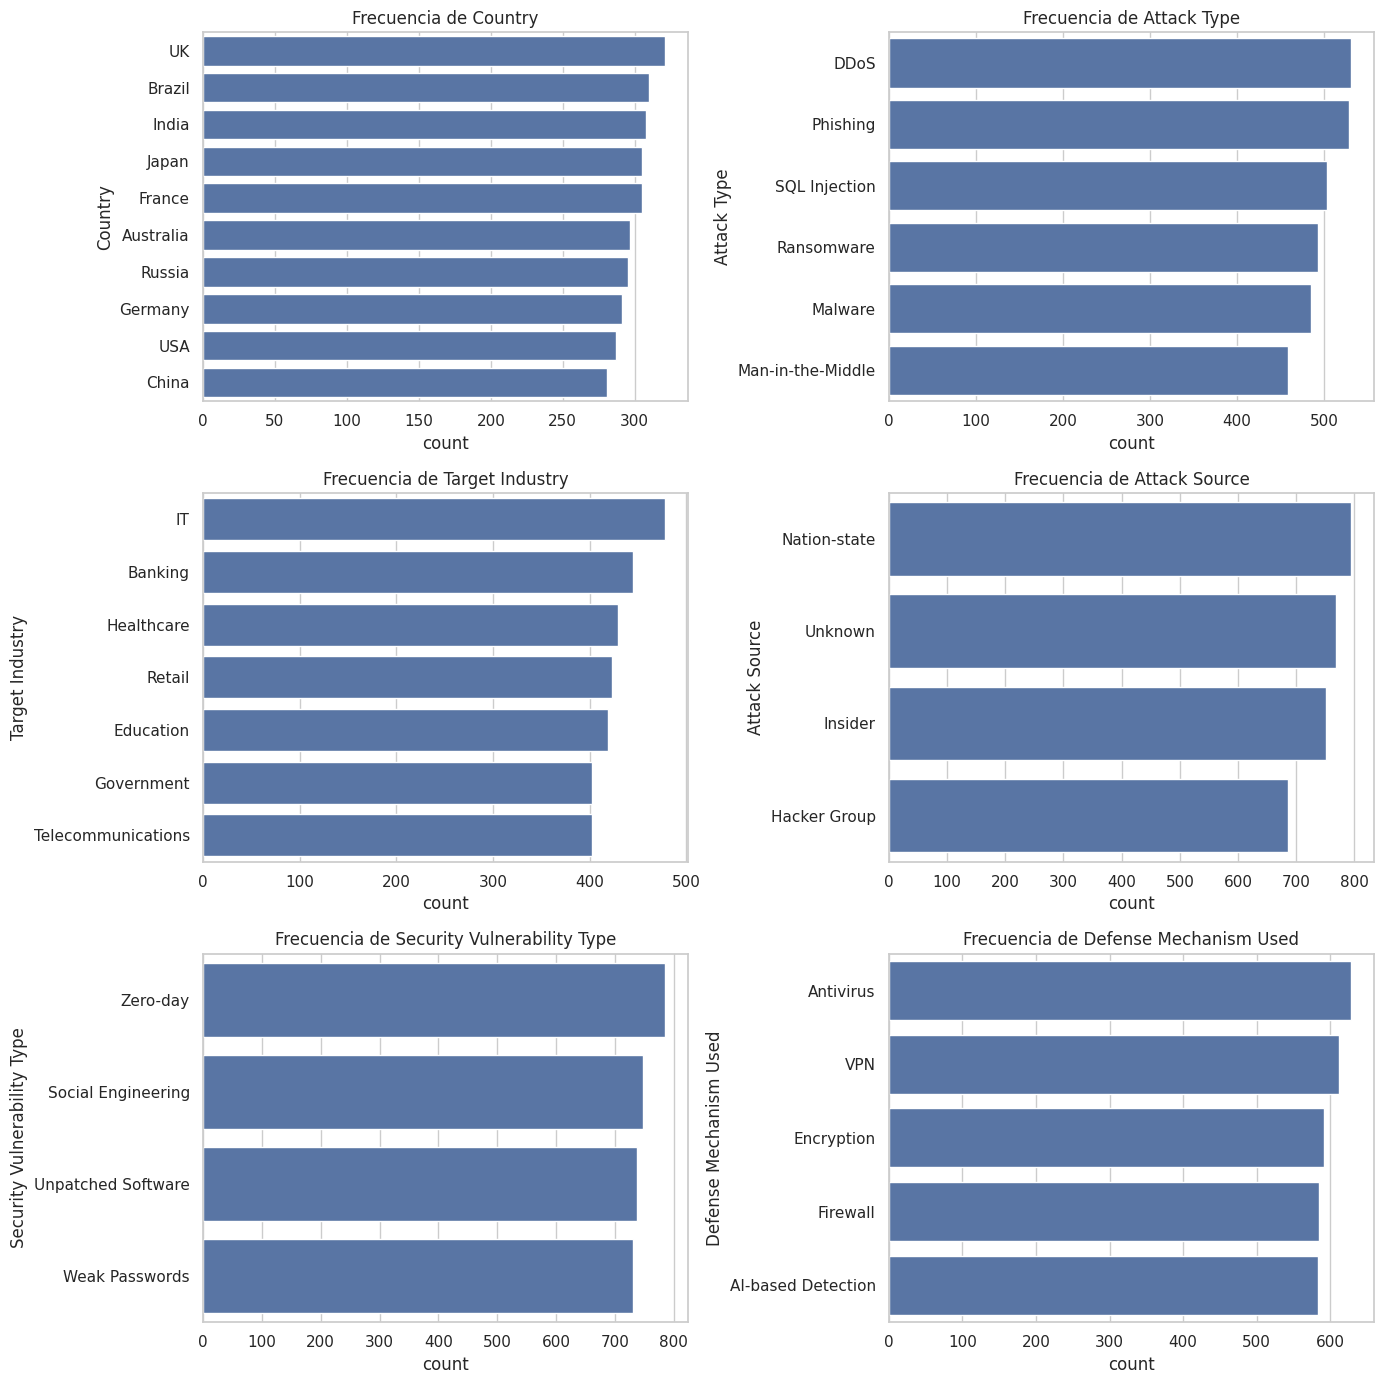

In [11]:
fig, axes = plt.subplots(3, 2, figsize=(14, 14))
axes = axes.flatten()
for ax, col in zip(axes, cat_cols):
    order = df[col].value_counts().index
    sns.countplot(y=col, data=df, order=order, ax=ax, color="#4C72B0")
    ax.set_title(f"Frecuencia de {col}")
plt.tight_layout()
plt.show()


## 6. Relaciones entre variables

### 6.1 Matriz de correlación (variables numéricas)

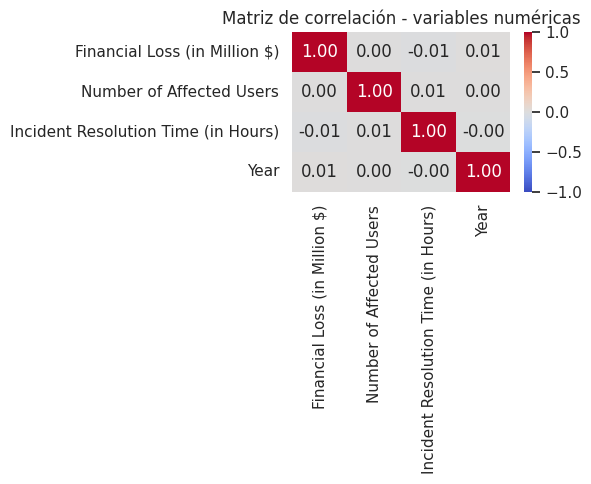

In [12]:
corr = df[num_cols].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Matriz de correlación - variables numéricas")
plt.tight_layout()
plt.show()


### 6.2 Pérdida financiera por tipo de ataque y por sector

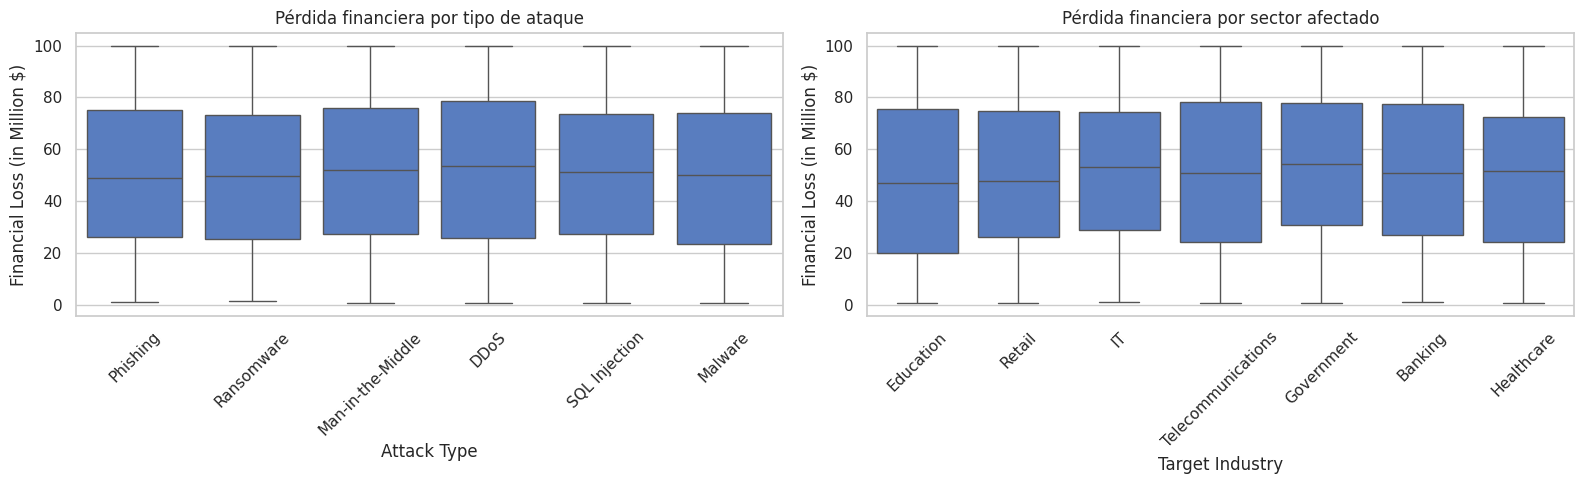

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.boxplot(x="Attack Type", y="Financial Loss (in Million $)", data=df, ax=axes[0])
axes[0].set_title("Pérdida financiera por tipo de ataque")
axes[0].tick_params(axis="x", rotation=45)

sns.boxplot(x="Target Industry", y="Financial Loss (in Million $)", data=df, ax=axes[1])
axes[1].set_title("Pérdida financiera por sector afectado")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


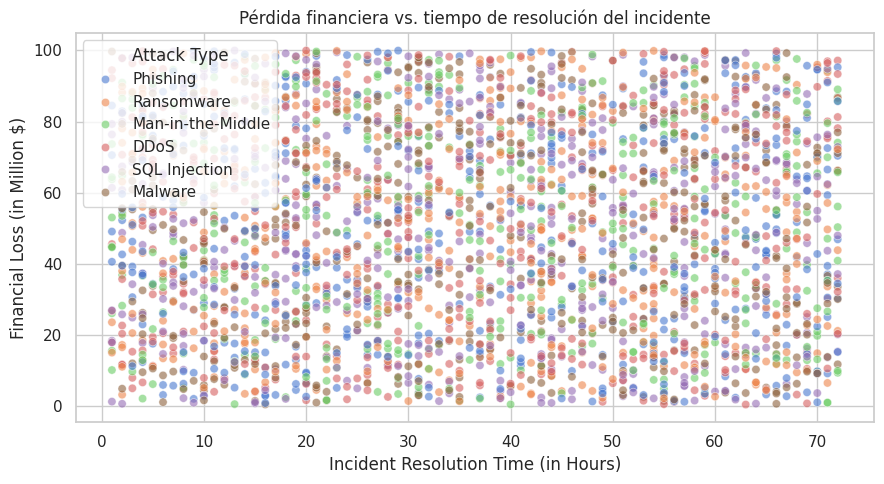

In [14]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(
    x="Incident Resolution Time (in Hours)",
    y="Financial Loss (in Million $)",
    hue="Attack Type",
    data=df,
    alpha=0.6,
    ax=ax,
)
ax.set_title("Pérdida financiera vs. tiempo de resolución del incidente")
plt.tight_layout()
plt.show()


## 7. Construcción de la variable objetivo de severidad

Siguiendo la definición del problema de la Sección 0 de este notebook, se define la variable de severidad
$Y \in \{\text{Low}, \text{Medium}, \text{High}\}$ discretizando el impacto
combinado de `Financial Loss` y `Incident Resolution Time` mediante terciles.

=== Diagnóstico de Balance: Dataset Completo (Severity) ===
  Clase Low: 1000 muestras (33.33%)
  Clase Medium: 1000 muestras (33.33%)
  Clase High: 1000 muestras (33.33%)
  Razón de desbalance (IR): 1.0000
  Veredicto: BALANCEADO (Criterio: IR <= 1.5 y |p_k - 1/3| <= 0.05)
  → Balance óptimo confirmado: la razón de desbalance y proporciones satisfacen los criterios establecidos.



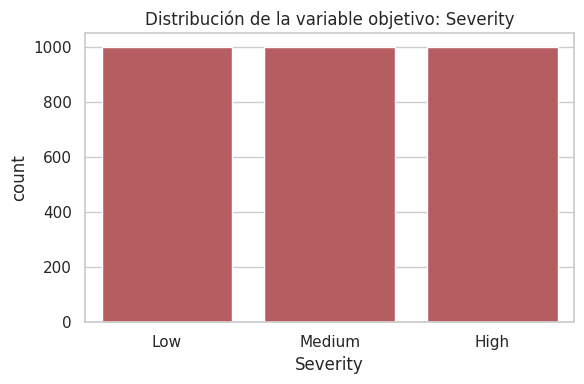

In [15]:
# Índice de impacto combinado (promedio de los rangos percentiles de ambas variables)
df["_rank_loss"] = df["Financial Loss (in Million $)"].rank(pct=True)
df["_rank_time"] = df["Incident Resolution Time (in Hours)"].rank(pct=True)
df["Impact_Score"] = (df["_rank_loss"] + df["_rank_time"]) / 2

df["Severity"] = pd.qcut(
    df["Impact_Score"], q=3, labels=["Low", "Medium", "High"]
)

df.drop(columns=["_rank_loss", "_rank_time"], inplace=True)

# -----------------------------------------------------------------
# Función de diagnóstico formal de balance de clases (TAREA 2.1)
# -----------------------------------------------------------------
def diagnose_balance(y, name="Target", tol=0.05):
    """
    Diagnostica el balance de clases de una serie o arreglo y.
    Calcula e imprime conteos, proporciones y la razón de desbalance IR = max(n_k)/min(n_k).
    Retorna (IR, ok), donde ok=True si IR <= 1.5 y toda proporción está a <= tol de 1/3.
    """
    counts = pd.Series(y).value_counts().sort_index()
    total = len(y)
    props = counts / total
    ir = float(counts.max() / counts.min()) if counts.min() > 0 else float(np.inf)

    target_prop = 1.0 / len(counts)  # 1/3 para clasificación triclase
    ok = bool((ir <= 1.5) and all(abs(p - target_prop) <= tol for p in props))
    verdict = "BALANCEADO" if ok else "DESBALANCEADO"

    print(f"=== Diagnóstico de Balance: {name} ===")
    for cls, cnt in counts.items():
        print(f"  Clase {cls}: {cnt} muestras ({props[cls]*100:.2f}%)")
    print(f"  Razón de desbalance (IR): {ir:.4f}")
    print(f"  Veredicto: {verdict} (Criterio: IR <= 1.5 y |p_k - 1/3| <= {tol:.2f})")
    print(f"  → {'Balance óptimo confirmado: la razón de desbalance y proporciones satisfacen los criterios establecidos.' if ok else 'Desbalance detectado: se requiere intervención en el muestreo.'}\n")
    return ir, ok

# Diagnóstico sobre el dataset completo (TAREA 2.2)
ir_full, ok_full = diagnose_balance(df["Severity"], name="Dataset Completo (Severity)")

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(x="Severity", data=df, order=["Low", "Medium", "High"], color="#C44E52", ax=ax)
ax.set_title("Distribución de la variable objetivo: Severity")
plt.tight_layout()
plt.show()

## 8. Imputación de datos faltantes

Conforme a la estrategia de preprocesamiento de este notebook: mediana para variables numéricas
y moda para variables categóricas. Esta celda se ejecuta de forma condicional
(solo actúa si existen valores nulos).

In [16]:
df_imputed = df.copy()

for col in num_cols:
    if df_imputed[col].isnull().sum() > 0:
        mediana = df_imputed[col].median()
        df_imputed[col] = df_imputed[col].fillna(mediana)
        print(f"Imputado '{col}' con la mediana = {mediana:.2f}")

for col in cat_cols:
    if df_imputed[col].isnull().sum() > 0:
        moda = df_imputed[col].mode()[0]
        df_imputed[col] = df_imputed[col].fillna(moda)
        print(f"Imputado '{col}' con la moda = {moda}")

print()
print("Valores nulos restantes:", df_imputed.isnull().sum().sum())



Valores nulos restantes: 0


## 9. Codificación de variables y partición de datos

- **Espacio de características antecedentes ($t=0$):** Se excluyen `Financial Loss`, `Incident Resolution Time` e `Impact_Score` para evitar *Data Leakage*.
- **One-Hot Encoding** con `drop_first=True` para variables categóricas nominales ($D=32$ columnas).
- **Partición Holdout estratificada 80/20** (`random_state=42`), con mapeo de clases a enteros: `Low`: 0, `Medium`: 1, `High`: 2.
- **Estandarización Z-score** (`StandardScaler`) ajustada exclusivamente sobre el conjunto de entrenamiento para prevenir fuga estadística.

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# -----------------------------------------------------------------
# Restricción al espacio de características antecedentes (t=0)
# -----------------------------------------------------------------
cat_cols = ['Country', 'Attack Type', 'Target Industry', 'Attack Source',
            'Security Vulnerability Type', 'Defense Mechanism Used']
cat_vars = cat_cols.copy()

feature_cols = ['Country', 'Year', 'Attack Type', 'Target Industry',
                'Number of Affected Users', 'Attack Source',
                'Security Vulnerability Type', 'Defense Mechanism Used']

X_raw = df_imputed[feature_cols].copy()
Y_raw = df_imputed['Severity'].copy()

# -----------------------------------------------------------------
# One-Hot Encoding con drop_first=True
# -----------------------------------------------------------------
X_encoded = pd.get_dummies(X_raw, columns=cat_cols, drop_first=True)
D = X_encoded.shape[1]
print(f'=== Espacio de Características Post-Encoding ===')
print(f'D = {D} características binarias/numéricas')
print(f'Variables: {list(X_encoded.columns)}')

# -----------------------------------------------------------------
# Partición Holdout estratificada 80/20
# -----------------------------------------------------------------
X_train, X_test, y_train_str, y_test_str = train_test_split(
    X_encoded, Y_raw, test_size=0.20, random_state=42, stratify=Y_raw
)

# Mapeo numérico de clases
label_map     = {'Low': 0, 'Medium': 1, 'High': 2}
inv_label_map = {0: 'Low', 1: 'Medium', 2: 'High'}
y_train = y_train_str.map(label_map).values
y_test  = y_test_str.map(label_map).values

# Diagnóstico de balance en Train y Test (TAREA 2.2)
ir_tr, ok_tr = diagnose_balance(y_train_str, name="y_train (Holdout 80%)")
ir_te, ok_te = diagnose_balance(y_test_str, name="y_test (Holdout 20%)")

# -----------------------------------------------------------------
# Estandarización Z-score ajustada exclusivamente sobre Train
# -----------------------------------------------------------------
num_scale_cols = ['Number of Affected Users', 'Year']
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled  = X_test.copy()
X_train_scaled[num_scale_cols] = scaler.fit_transform(X_train[num_scale_cols])
X_test_scaled[num_scale_cols]  = scaler.transform(X_test[num_scale_cols])

feature_names = list(X_train_scaled.columns)

# Resumen del preprocesamiento
print('=== Resumen del Preprocesamiento ===')
print(f'Muestras de entrenamiento:  {X_train_scaled.shape[0]} ({X_train_scaled.shape[0]/len(df)*100:.0f}%)')
print(f'Muestras de prueba:         {X_test_scaled.shape[0]} ({X_test_scaled.shape[0]/len(df)*100:.0f}%)')
print(f'Dimensión del espacio: D = {D} características')
print(f'Distribución Train: {pd.Series(y_train_str).value_counts().to_dict()}')
print(f'Distribución Test:  {pd.Series(y_test_str).value_counts().to_dict()}')
print(f'\nEstandarización aplicada a: {num_scale_cols}')
print(f'  Ajuste SOLO sobre Train → se transforma Test con parámetros del Train')
print(f'  (previene fuga de información estadística hacia el conjunto de prueba)')

X_encoded.head()

=== Espacio de Características Post-Encoding ===
D = 32 características binarias/numéricas
Variables: ['Year', 'Number of Affected Users', 'Country_Brazil', 'Country_China', 'Country_France', 'Country_Germany', 'Country_India', 'Country_Japan', 'Country_Russia', 'Country_UK', 'Country_USA', 'Attack Type_Malware', 'Attack Type_Man-in-the-Middle', 'Attack Type_Phishing', 'Attack Type_Ransomware', 'Attack Type_SQL Injection', 'Target Industry_Education', 'Target Industry_Government', 'Target Industry_Healthcare', 'Target Industry_IT', 'Target Industry_Retail', 'Target Industry_Telecommunications', 'Attack Source_Insider', 'Attack Source_Nation-state', 'Attack Source_Unknown', 'Security Vulnerability Type_Unpatched Software', 'Security Vulnerability Type_Weak Passwords', 'Security Vulnerability Type_Zero-day', 'Defense Mechanism Used_Antivirus', 'Defense Mechanism Used_Encryption', 'Defense Mechanism Used_Firewall', 'Defense Mechanism Used_VPN']
=== Diagnóstico de Balance: y_train (Holdout

,Year,Number of Affected Users,Country_Brazil,Country_China,Country_France,Country_Germany,Country_India,Country_Japan,Country_Russia,Country_UK,...,Attack Source_Insider,Attack Source_Nation-state,Attack Source_Unknown,Security Vulnerability Type_Unpatched Software,Security Vulnerability Type_Weak Passwords,Security Vulnerability Type_Zero-day,Defense Mechanism Used_Antivirus,Defense Mechanism Used_Encryption,Defense Mechanism Used_Firewall,Defense Mechanism Used_VPN
0,2019,773169,False,True,False,False,False,False,False,False,...,False,False,False,True,False,False,False,False,False,True
1,2019,295961,False,True,False,False,False,False,False,False,...,False,False,False,True,False,False,False,False,True,False
2,2017,605895,False,False,False,False,True,False,False,False,...,False,False,False,False,True,False,False,False,False,True
3,2024,659320,False,False,False,False,False,False,False,True,...,False,True,False,False,False,False,False,False,False,False
4,2018,810682,False,False,False,True,False,False,False,False,...,True,False,False,False,False,False,False,False,False,True


## 10. Conclusiones del EDA

- La base de datos contiene 3.000 registros y 10 variables, sin un porcentaje relevante de valores nulos.
- Las variables numéricas (`Financial Loss`, `Number of Affected Users`, `Incident Resolution Time`)
  presentan distribuciones relativamente dispersas, sin una tendencia temporal marcada por año.
- No se observan correlaciones lineales fuertes entre las variables numéricas, lo que sugiere que
  la severidad del incidente depende de una combinación de factores categóricos (tipo de ataque,
  sector, vulnerabilidad) más que de una única variable numérica.
- La variable de severidad construida por terciles (`Low`, `Medium`, `High`) queda balanceada,
  lo cual es adecuado para el entrenamiento de un clasificador multiclase.
- Estos hallazgos respaldan el paradigma de aprendizaje supervisado enfocado exclusivamente en clasificación multiclase planteado en la Sección 0 de este notebook, garantizando la capacidad de triaje automático en tiempo real ($t=0$) sin incurrir en data leakage.

# Parte II: Entrenamiento, Evaluación de Modelos y Reducción de Dimensión

Esta segunda parte desarrolla la evaluación rigurosa de 5 familias de aprendizaje supervisado y la reducción de dimensión lineal (PCA) y no lineal (UMAP), con estricta continuidad metodológica respecto a los datos y el preprocesamiento antecedentes establecidos en la Parte I.

## Sección 1: Entrenamiento y Evaluación (30%)

### 1.1 Configuración Experimental

#### 1.1.A Metodología de Validación y Gestión del Balance de Clases

El esquema de validación implementado combina dos particiones complementarias para garantizar una estimación no sesgada del desempeño generalizable:

**1. Partición Holdout Estratificada (80/20):**  
El conjunto global ($N = 3\,000$ incidentes) se divide en:
- **Entrenamiento**: $N_{\text{train}} = 2\,400$ muestras (≈$800$ por clase; el conteo exacto se verifica con `diagnose_balance`).
- **Prueba independiente (*Holdout test*)**: $N_{\text{test}} = 600$ muestras (≈$200$ por clase).

El conjunto de prueba permanece estrictamente sellado durante la sintonización y selección de modelos, utilizándose exclusivamente para la evaluación final de generalización.

**2. Validación Cruzada Estratificada ($K = 5$ pliegues):**  
Se aplica sobre los 2,400 registros de entrenamiento durante la exploración de hiperparámetros. En cada pliegue:
- **Entrenamiento interno**: 1,920 muestras (80% de 2,400, ≈$640$ por clase).
- **Validación interna**: 480 muestras (20% de 2,400, ≈$160$ por clase).

**3. Estimación de Intervalos de Confianza con distribución $t$ de Student:**  
Al disponer de un número finito pequeño de pliegues ($K = 5$), la aproximación normal asintótica ($z = 1.96$) subestima la incertidumbre muestral. Por tanto, se utiliza la distribución $t$ de Student con $K - 1 = 4$ grados de libertad:
$$\text{IC}_{95\%} = \bar{x} \pm t_{0.975, K-1} \cdot \frac{s}{\sqrt{K}}$$
donde $t_{0.975, 4} = \text{scipy.stats.t.ppf}(0.975, 4) \approx 2.7764$.

**4. Criterio de Selección de Modelos:**  
- Los hiperparámetros óptimos de cada modelo se eligen **estrictamente por el F1-Score Macro medio de VALIDACIÓN** en los 5 pliegues de validación cruzada.
- Los dos mejores modelos globales (`top2_models`) para la etapa de reducción de dimensión se seleccionan **exclusivamente por F1-macro de VALIDACIÓN** (nunca observando el conjunto de prueba).

**5. Tratamiento y Gestión del Balance de Clases:**  
- **Diagnóstico cuantitativo**: Mediante `diagnose_balance`, se verifica la razón de desbalance $IR = \frac{\max(n_k)}{\min(n_k)}$ y las proporciones por clase.
- **Regla de decisión**: Se declara "BALANCEADO" si $IR \le 1.5$ y $|p_k - 1/3| \le 0.05$ en todas las clases.
- **Estrategia automática (`BALANCE_STRATEGY`)**: Si es BALANCEADO, se adopta `'none'`. Si se detectara desbalance, se aplicaría `class_weight='balanced'` en modelos que lo admiten (Logistic Regression, Random Forest, SVC) y `RandomOverSampler` en los que no (KNN, MLP).
- **Garantía anti-fuga (*anti-leakage*)**: En caso de aplicarse re-muestreo (`sampler`), este se ejecuta estrictamente dentro de `run_cv` aplicando `fit_resample` exclusivamente sobre los datos de entrenamiento de cada pliegue ($X_{tr}, y_{tr}$), sin que el muestreador jamás tenga contacto con la validación interna ($X_{val}$) ni con el conjunto de prueba independiente ($X_{test}$).
- **Origen del balance**: Se enfatiza que el balance ($N_k \approx 1\,000$ global, $\approx 640$ por clase en entrenamiento de cada pliegue) es producto de la discretización por terciles (`pd.qcut`) del `Impact_Score` antecedente y no de un re-muestreo sintético.
- **Prueba de estrés de balance (Tabla 3B y Figura 3B):** como el balance de este dataset es nativo (IR = 1.0), ninguna técnica se activa en el flujo principal y la Tabla 3 resulta idéntica por construcción. Para demostrar que la gestión del balance funciona cuando existe desbalance, se genera un subconjunto de entrenamiento con IR = 5.0 (800/400/160 muestras) y se comparan `none`, `class_weight`, `RandomOverSampler` y `RandomUnderSampler`; el remuestreo se aplica solo dentro del pliegue de entrenamiento y el conjunto de prueba no se usa.


In [18]:
# -----------------------------------------------------------------
# Configuración del entorno de experimentación de la Sección 1
# -----------------------------------------------------------------
import os
import scipy.stats as stats
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix
)
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from imblearn.over_sampling import RandomOverSampler

# -----------------------------------------------------------------
# Verificación del diagnóstico de balance en los pliegues de CV
# -----------------------------------------------------------------
print("=== Diagnóstico de Balance en los 5 Pliegues de CV (K=5) sobre Train ===")
skf_diag = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for fold_idx, (tr_idx, val_idx) in enumerate(skf_diag.split(X_train_scaled, y_train), 1):
    diagnose_balance(y_train[tr_idx], name=f"Pliegue {fold_idx} [Train CV - 1920 muestras]")
    diagnose_balance(y_train[val_idx], name=f"Pliegue {fold_idx} [Val CV - 480 muestras]")

# Regla de decisión automática
ir_train, is_train_balanced = diagnose_balance(y_train, name="y_train (Holdout Train)")
BALANCE_STRATEGY = 'none' if is_train_balanced else 'class_weight'
print(f"Estrategia de balance seleccionada automáticamente: BALANCE_STRATEGY = '{BALANCE_STRATEGY}'")

# Despachador de configuración de balance por modelo
SAMPLER = RandomOverSampler(random_state=42)
SUPPORTS_CW = {'LogisticRegression', 'RandomForest', 'SVM'}

def balance_for(model_name):
    """Retorna (kwargs_modelo, sampler_cv) según BALANCE_STRATEGY."""
    if BALANCE_STRATEGY == 'class_weight' and model_name in SUPPORTS_CW:
        return {'class_weight': 'balanced'}, None
    if BALANCE_STRATEGY in ('class_weight', 'random_oversample'):
        return {}, SAMPLER
    return {}, None

# -----------------------------------------------------------------
# Función genérica de construcción de modelos (build_model)
# -----------------------------------------------------------------
def build_model(name, params):
    """Instancia el clasificador solicitado integrando la estrategia de balance y semilla 42."""
    cw, _ = balance_for(name)
    p = {**params, **cw}
    if name == 'LogisticRegression':
        return LogisticRegression(max_iter=1000, random_state=42, solver='lbfgs', **p)
    elif name == 'KNN':
        metric = p.get('metric', 'euclidean')
        return KNeighborsClassifier(n_neighbors=p['n_neighbors'], weights=p.get('weights', 'distance'), metric=metric)
    elif name == 'RandomForest':
        return RandomForestClassifier(random_state=42, n_jobs=-1, **p)
    elif name == 'MLP':
        return MLPClassifier(max_iter=500, random_state=42, **p)
    elif name == 'SVM':
        return SVC(probability=True, random_state=42, **p)
    else:
        raise ValueError(f"Modelo desconocido: {name}")

# -----------------------------------------------------------------
# Funciones de evaluación y validación cruzada con t de Student
# -----------------------------------------------------------------
def evaluate_metrics(y_true, y_pred, y_proba=None):
    """Calcula el conjunto completo de métricas de desempeño para clasificación multiclase."""
    acc   = accuracy_score(y_true, y_pred)
    b_acc = balanced_accuracy_score(y_true, y_pred)
    prec  = precision_score(y_true, y_pred, average='macro', zero_division=0)
    rec   = recall_score(y_true, y_pred, average='macro', zero_division=0)
    f1    = f1_score(y_true, y_pred, average='macro', zero_division=0)
    roc_auc = np.nan
    if y_proba is not None:
        try:
            roc_auc = roc_auc_score(y_true, y_proba, multi_class='ovr', average='macro')
        except Exception:
            roc_auc = np.nan
    return {
        'accuracy': float(acc),
        'balanced_accuracy': float(b_acc),
        'precision_macro': float(prec),
        'recall_macro': float(rec),
        'f1_macro': float(f1),
        'roc_auc_macro': float(roc_auc) if not np.isnan(roc_auc) else None
    }

def run_cv(model_fn, X, y, n_splits=5, seed=42, sampler=None):
    """Valida con StratifiedKFold (K=5) calculando intervalos de confianza con t de Student."""
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    train_scores, val_scores = [], []

    for tr_idx, val_idx in skf.split(X, y):
        if isinstance(X, pd.DataFrame):
            X_tr, X_val = X.iloc[tr_idx].copy(), X.iloc[val_idx].copy()
        else:
            X_tr, X_val = X[tr_idx].copy(), X[val_idx].copy()
        y_tr, y_val = y[tr_idx].copy(), y[val_idx].copy()

        # Sampler aplicado estrictamente en el pliegue de entrenamiento (anti-leakage)
        if sampler is not None:
            X_tr, y_tr = sampler.fit_resample(X_tr, y_tr)

        clf = model_fn()
        clf.fit(X_tr, y_tr)

        y_tr_pred  = clf.predict(X_tr)
        y_tr_proba = clf.predict_proba(X_tr) if hasattr(clf, 'predict_proba') else None
        train_scores.append(evaluate_metrics(y_tr, y_tr_pred, y_tr_proba))

        y_val_pred  = clf.predict(X_val)
        y_val_proba = clf.predict_proba(X_val) if hasattr(clf, 'predict_proba') else None
        val_scores.append(evaluate_metrics(y_val, y_val_pred, y_val_proba))

    def aggregate(scores):
        agg = {}
        for m in scores[0].keys():
            vals = [s[m] for s in scores if s[m] is not None]
            if vals:
                mean = float(np.mean(vals))
                std  = float(np.std(vals, ddof=1)) if len(vals) > 1 else 0.0
                t_crit = float(stats.t.ppf(0.975, df=len(vals)-1)) if len(vals) > 1 else 1.96
                ci   = t_crit * (std / np.sqrt(len(vals)))
                agg[m] = {'mean': mean, 'std': std, 't_crit': t_crit,
                          'ci_low': mean - ci, 'ci_high': mean + ci}
            else:
                agg[m] = None
        return agg

    return aggregate(train_scores), aggregate(val_scores)

def bootstrap_test_metrics(y_true, y_pred, y_proba=None, n_boot=1000, seed=42):
    """Estima intervalos de confianza al 95% en test mediante remuestreo bootstrap (1000 réplicas)."""
    rng = np.random.RandomState(seed)
    n = len(y_true)
    boots = {'f1_macro': [], 'accuracy': [], 'balanced_accuracy': [], 'roc_auc_macro': []}
    for _ in range(n_boot):
        idx = rng.randint(0, n, size=n)
        yt, yp = y_true[idx], y_pred[idx]
        boots['f1_macro'].append(f1_score(yt, yp, average='macro', zero_division=0))
        boots['accuracy'].append(accuracy_score(yt, yp))
        boots['balanced_accuracy'].append(balanced_accuracy_score(yt, yp))
        if y_proba is not None:
            try:
                boots['roc_auc_macro'].append(roc_auc_score(yt, y_proba[idx], multi_class='ovr', average='macro'))
            except Exception:
                pass
    cis = {}
    for k, vals in boots.items():
        if vals:
            cis[k] = (float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5)))
        else:
            cis[k] = None
    return cis

print("Entorno de experimentación inicializado correctamente.")

=== Diagnóstico de Balance en los 5 Pliegues de CV (K=5) sobre Train ===
=== Diagnóstico de Balance: Pliegue 1 [Train CV - 1920 muestras] ===
  Clase 0: 640 muestras (33.33%)
  Clase 1: 640 muestras (33.33%)
  Clase 2: 640 muestras (33.33%)
  Razón de desbalance (IR): 1.0000
  Veredicto: BALANCEADO (Criterio: IR <= 1.5 y |p_k - 1/3| <= 0.05)
  → Balance óptimo confirmado: la razón de desbalance y proporciones satisfacen los criterios establecidos.

=== Diagnóstico de Balance: Pliegue 1 [Val CV - 480 muestras] ===
  Clase 0: 160 muestras (33.33%)
  Clase 1: 160 muestras (33.33%)
  Clase 2: 160 muestras (33.33%)
  Razón de desbalance (IR): 1.0000
  Veredicto: BALANCEADO (Criterio: IR <= 1.5 y |p_k - 1/3| <= 0.05)
  → Balance óptimo confirmado: la razón de desbalance y proporciones satisfacen los criterios establecidos.

=== Diagnóstico de Balance: Pliegue 2 [Train CV - 1920 muestras] ===
  Clase 0: 640 muestras (33.33%)
  Clase 1: 640 muestras (33.33%)
  Clase 2: 640 muestras (33.33%)
  

#### 1.1.B Malla de Hiperparámetros y Definición Unificada de Modelos

Para garantizar una exploración sistemática y reproducible, las mallas completas de hiperparámetros se definen centralizadamente en la estructura `PARAM_GRIDS`. La Tabla 1 sintetiza las familias evaluadas, los hiperparámetros sintonizados y las combinaciones examinadas, construida directamente a partir de dicha definición para evitar discrepancias entre la especificación documental y el código ejecutado.

In [19]:
# -----------------------------------------------------------------
# Definición centralizada de mallas de hiperparámetros (PARAM_GRIDS)
# -----------------------------------------------------------------
PARAM_GRIDS = {
    'LogisticRegression': [
        {'C': c} for c in [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
    ],
    'KNN': [
        {'n_neighbors': k, 'weights': 'distance'} for k in [3, 5, 7, 11, 15, 21, 31, 45]
    ],
    'RandomForest': [
        {'n_estimators': n, 'max_depth': d}
        for n in [50, 100, 200]
        for d in [5, 10, 15, None]
    ],
    'MLP': [
        {'hidden_layer_sizes': h, 'alpha': a, 'activation': 'relu'}
        for h in [(32,), (64,), (64, 32), (100,)]
        for a in [0.0001, 0.001, 0.01, 0.1]
    ],
    'SVM': (
        [{'C': c, 'kernel': 'linear'} for c in [0.1, 1.0, 10.0]] +
        [{'C': c, 'kernel': 'rbf', 'gamma': g}
         for c in [0.1, 1.0, 10.0]
         for g in ['scale', 0.01]]
    )
}

# Generación programática de la Tabla 1
table1_rows = [
    {
        'Modelo': 'LogisticRegression',
        'Familia': 'Paramétrico Lineal',
        'Hiperparámetros Explorados': 'C (inverso de regularización L2)',
        'Valores en la Malla': '{0.001, 0.01, 0.1, 1.0, 10.0, 100.0}, penalización L2 fija',
        'N° Combinaciones': len(PARAM_GRIDS['LogisticRegression'])
    },
    {
        'Modelo': 'KNN',
        'Familia': 'No Paramétrico (Instancias)',
        'Hiperparámetros Explorados': 'k (vecinos cercanos), ponderación',
        'Valores en la Malla': "k ∈ {3, 5, 7, 11, 15, 21, 31, 45}, weights='distance'",
        'N° Combinaciones': len(PARAM_GRIDS['KNN'])
    },
    {
        'Modelo': 'RandomForest',
        'Familia': 'Ensamble de Árboles (Bagging)',
        'Hiperparámetros Explorados': 'n_estimators, max_depth',
        'Valores en la Malla': 'n_est ∈ {50, 100, 200} × d_max ∈ {5, 10, 15, None}',
        'N° Combinaciones': len(PARAM_GRIDS['RandomForest'])
    },
    {
        'Modelo': 'MLP',
        'Familia': 'Red Neuronal Artificial',
        'Hiperparámetros Explorados': 'hidden_layer_sizes, alpha (L2)',
        'Valores en la Malla': 'capas ∈ {(32,), (64,), (64,32), (100,)} × α ∈ {1e-4, 1e-3, 1e-2, 1e-1}, relu',
        'N° Combinaciones': len(PARAM_GRIDS['MLP'])
    },
    {
        'Modelo': 'SVM',
        'Familia': 'Métodos de Kernel',
        'Hiperparámetros Explorados': 'kernel, C, gamma',
        'Valores en la Malla': "linear: C ∈ {0.1, 1, 10}; rbf: C ∈ {0.1, 1, 10} × γ ∈ {'scale', 0.01}",
        'N° Combinaciones': len(PARAM_GRIDS['SVM'])
    }
]

df_tabla1 = pd.DataFrame(table1_rows)

print("Tabla 1: Malla de hiperparámetros explorada para las 5 familias de clasificadores")
display(df_tabla1)

Tabla 1: Malla de hiperparámetros explorada para las 5 familias de clasificadores


,Modelo,Familia,Hiperparámetros Explorados,Valores en la Malla,N° Combinaciones
0,LogisticRegression,Paramétrico Lineal,C (inverso de regularización L2),"{0.001, 0.01, 0.1, 1.0, 10.0, 100.0}, penaliza...",6
1,KNN,No Paramétrico (Instancias),"k (vecinos cercanos), ponderación","k ∈ {3, 5, 7, 11, 15, 21, 31, 45}, weights='di...",8
2,RandomForest,Ensamble de Árboles (Bagging),"n_estimators, max_depth","n_est ∈ {50, 100, 200} × d_max ∈ {5, 10, 15, N...",12
3,MLP,Red Neuronal Artificial,"hidden_layer_sizes, alpha (L2)","capas ∈ {(32,), (64,), (64,32), (100,)} × α ∈ ...",16
4,SVM,Métodos de Kernel,"kernel, C, gamma","linear: C ∈ {0.1, 1, 10}; rbf: C ∈ {0.1, 1, 10...",9


#### 1.1.C Métricas de Desempeño y Justificación

Para la evaluación rigurosa del problema triclase de clasificación de severidad ($Y \in \{\text{Low}, \text{Medium}, \text{High}\}$), se define el siguiente conjunto de métricas:

- **F1-Score Macro (Métrica Principal de Selección):** Promedio no ponderado de las puntuaciones F1 de las tres clases ($F1_{\text{macro}} = \frac{1}{3}\sum_{k} F1_k$). Penaliza por igual los errores cometidos en cualquiera de las categorías de severidad, evitando que una clase oculte deficiencias en las demás.
- **Exactitud Global (Accuracy):** Proporción global de aciertos sobre el total de muestras evaluadas.
- **Exactitud Balanceada (Balanced Accuracy):** Promedio de las sensibilidades por clase ($\frac{1}{3}\sum_{k} \text{Recall}_k$). Es el análogo robusto de la exactitud frente a variaciones en la distribución de etiquetas.
- **Precisión y Sensibilidad Macro (Precision / Recall Macro):** Permiten diagnosticar el balance entre falsos positivos y falsos negativos en cada clase.
- **Macro ROC-AUC (One-vs-Rest):** Evalúa la capacidad promedio del clasificador para separar probabilísticamente cada nivel de severidad del resto.

> **Justificación del reporte con Intervalos de Confianza y Línea Base Aleatoria:**  
> Dado que el problema cuenta con 3 clases simétricas, un clasificador puramente aleatorio o no informativo obtiene una esperanza matemática de **$\text{F1-Macro} = 1/3 \approx 0.3333$** y $\text{Accuracy} = 0.3333$. El reporte obligatorio de intervalos de confianza al 95% (calculados con la distribución $t$ de Student en validación cruzada y con bootstrap en prueba) permite discernir formalmente si el desempeño alcanzado por los modelos supera con significancia estadística dicha cota aleatoria o si se mantiene en el margen de ruido muestral.

### 1.2 Resultados Experimentales

A continuación se ejecuta la sintonización completa de hiperparámetros sobre las 5 familias de modelos empleando la función unificada `build_model` y la validación cruzada estratificada con $K=5$ pliegues. El conjunto de prueba permanece sellado hasta evaluar la configuración óptima seleccionada por validación.

In [20]:
# -----------------------------------------------------------------
# Ejecución sistemática de la exploración de hiperparámetros (K=5 CV)
# -----------------------------------------------------------------
experiment_log = {}

for m_name, grid in PARAM_GRIDS.items():
    print(f"\nEjecutando validación cruzada para {m_name} ({len(grid)} combinaciones)...")
    history = []
    cw, smp = balance_for(m_name)

    for p in grid:
        tr_m, val_m = run_cv(lambda p_curr=p: build_model(m_name, p_curr),
                             X_train_scaled, y_train, n_splits=5, seed=42, sampler=smp)
        history.append({'params': p, 'train': tr_m, 'val': val_m})

    # Selección del óptimo ESTRICTAMENTE por F1-Macro medio de VALIDACIÓN
    best_idx = int(np.argmax([h['val']['f1_macro']['mean'] for h in history]))
    best_params = history[best_idx]['params']
    best_val = history[best_idx]['val']
    best_train = history[best_idx]['train']

    # Ajuste final sobre X_train_scaled completo y evaluación en Test sellado
    X_tr_fit, y_tr_fit = smp.fit_resample(X_train_scaled, y_train) if smp is not None else (X_train_scaled, y_train)
    best_clf = build_model(m_name, best_params)
    best_clf.fit(X_tr_fit, y_tr_fit)

    pred_test = best_clf.predict(X_test_scaled)
    proba_test = best_clf.predict_proba(X_test_scaled) if hasattr(best_clf, 'predict_proba') else None

    test_metrics = evaluate_metrics(y_test, pred_test, proba_test)
    test_boot_ci = bootstrap_test_metrics(y_test, pred_test, proba_test, n_boot=1000, seed=42)

    experiment_log[m_name] = {
        'best_params': best_params,
        'history': history,
        'best_train': best_train,
        'best_val': best_val,
        'test': test_metrics,
        'test_ci': test_boot_ci,
        'pred_test': pred_test,
        'proba_test': proba_test,
        'best_clf': best_clf
    }

    val_f1 = best_val['f1_macro']
    print(f"  → Óptimo {m_name}: {best_params}")
    print(f"    Val  F1-Macro = {val_f1['mean']:.4f} ± {val_f1['std']:.4f} [{val_f1['ci_low']:.4f}, {val_f1['ci_high']:.4f}]")
    print(f"    Test F1-Macro = {test_metrics['f1_macro']:.4f} [IC95% boot: {test_boot_ci['f1_macro'][0]:.4f}, {test_boot_ci['f1_macro'][1]:.4f}]")

print("\nSintonización y evaluación de las 5 familias completada con éxito.")


Ejecutando validación cruzada para LogisticRegression (6 combinaciones)...
  → Óptimo LogisticRegression: {'C': 0.01}
    Val  F1-Macro = 0.3343 ± 0.0273 [0.3004, 0.3682]
    Test F1-Macro = 0.3582 [IC95% boot: 0.3238, 0.3971]

Ejecutando validación cruzada para KNN (8 combinaciones)...
  → Óptimo KNN: {'n_neighbors': 45, 'weights': 'distance'}
    Val  F1-Macro = 0.3369 ± 0.0154 [0.3178, 0.3559]
    Test F1-Macro = 0.3586 [IC95% boot: 0.3228, 0.3948]

Ejecutando validación cruzada para RandomForest (12 combinaciones)...
  → Óptimo RandomForest: {'n_estimators': 200, 'max_depth': 15}
    Val  F1-Macro = 0.3423 ± 0.0184 [0.3195, 0.3651]
    Test F1-Macro = 0.3450 [IC95% boot: 0.3065, 0.3844]

Ejecutando validación cruzada para MLP (16 combinaciones)...
  → Óptimo MLP: {'hidden_layer_sizes': (64, 32), 'alpha': 0.0001, 'activation': 'relu'}
    Val  F1-Macro = 0.3393 ± 0.0269 [0.3059, 0.3728]
    Test F1-Macro = 0.3381 [IC95% boot: 0.3020, 0.3791]

Ejecutando validación cruzada para SVM 

#### Análisis Gráfico del Efecto de Hiperparámetros

La Figura 1 ilustra el comportamiento del desempeño (F1-Score Macro) en entrenamiento y validación cruzada para cada una de las 5 familias de modelos a medida que varía su espacio de parámetros, incorporando las barras de error correspondientes a los intervalos de confianza al 95% calculados con la distribución $t$ de Student. El panel (f) consolida la comparación entre el desempeño de validación y la prueba independiente para las 5 configuraciones óptimas.

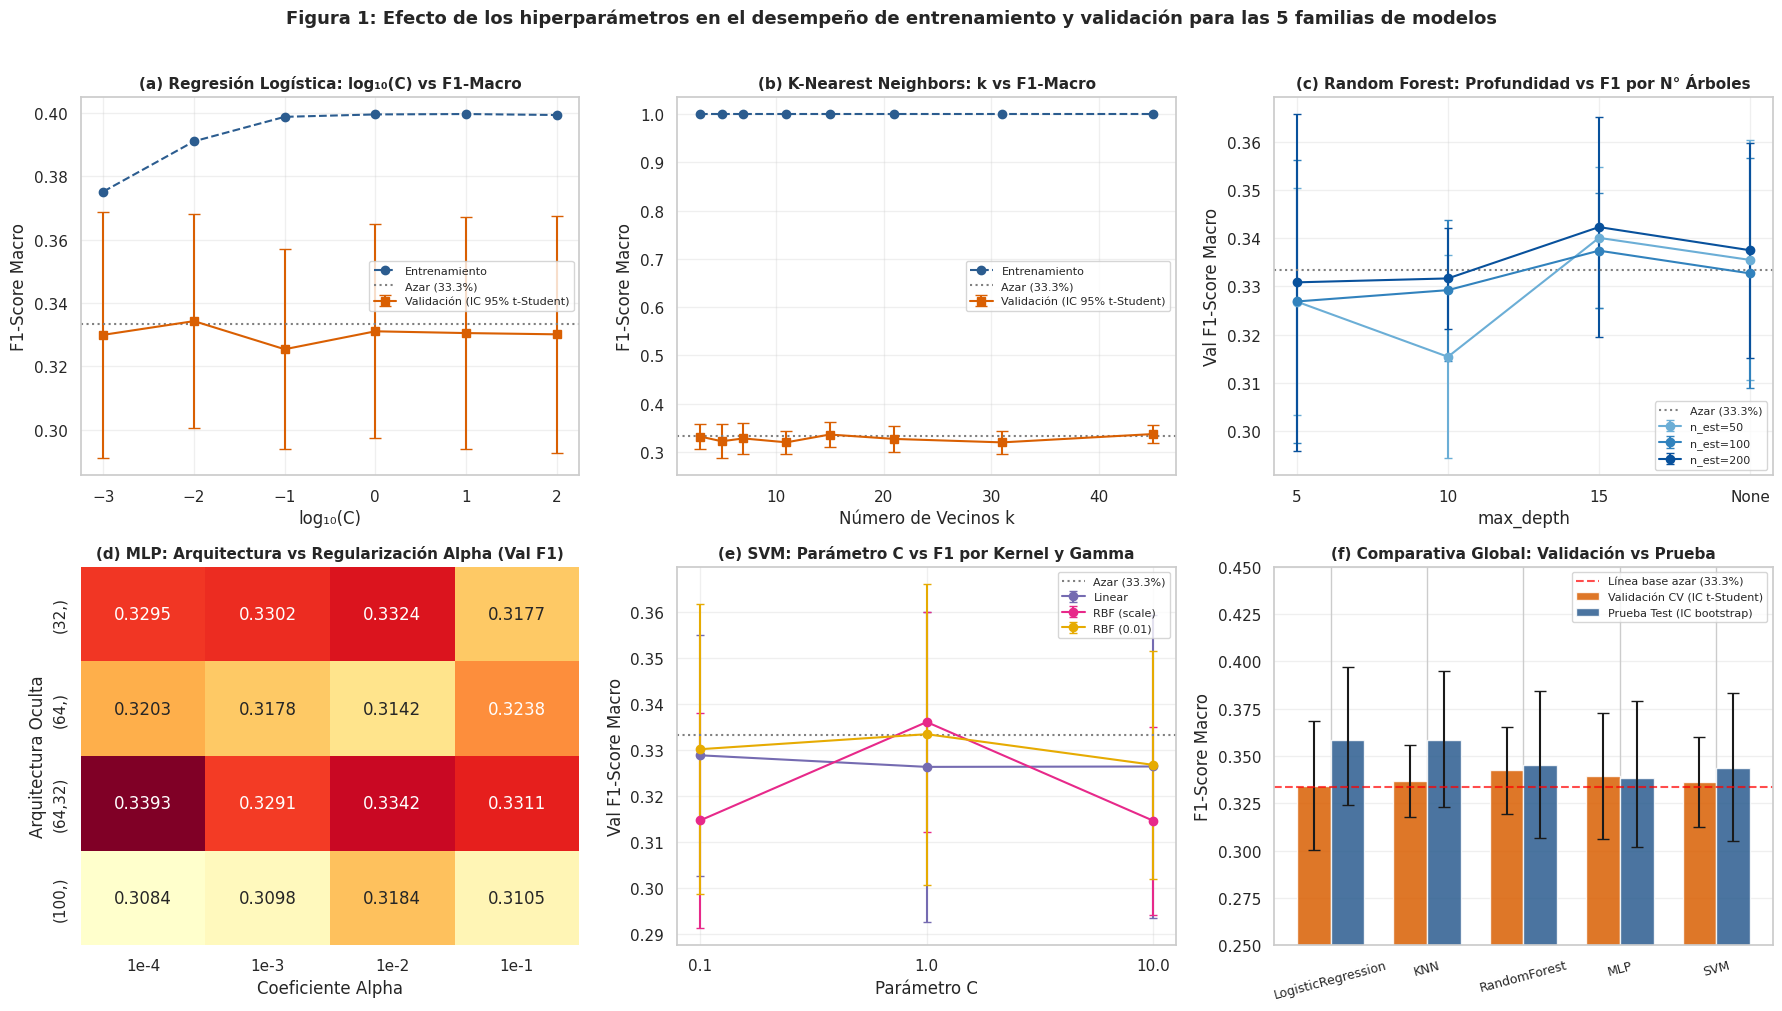

Figura 1 mostrada en el notebook.


In [21]:
# -----------------------------------------------------------------
# Generación de la Figura 1: Efecto de los Hiperparámetros
# -----------------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

col_tr = '#2b5c8f'
col_val = '#d95f02'

# (a) Regresión Logística: log10(C) vs F1-Macro
lr_hist = experiment_log['LogisticRegression']['history']
c_vals = [h['params']['C'] for h in lr_hist]
log_c = np.log10(c_vals)
tr_lr = [h['train']['f1_macro']['mean'] for h in lr_hist]
val_lr = [h['val']['f1_macro']['mean'] for h in lr_hist]
val_err_lr = [h['val']['f1_macro']['t_crit'] * h['val']['f1_macro']['std'] / np.sqrt(5) for h in lr_hist]

axes[0].plot(log_c, tr_lr, 'o--', color=col_tr, label='Entrenamiento')
axes[0].errorbar(log_c, val_lr, yerr=val_err_lr, fmt='s-', color=col_val, capsize=4, label='Validación (IC 95% t-Student)')
axes[0].axhline(y=1/3, color='gray', linestyle=':', label='Azar (33.3%)')
axes[0].set_title('(a) Regresión Logística: log₁₀(C) vs F1-Macro', fontsize=11, fontweight='bold')
axes[0].set_xlabel('log₁₀(C)'); axes[0].set_ylabel('F1-Score Macro'); axes[0].legend(fontsize=8); axes[0].grid(True, alpha=0.3)

# (b) KNN: k vs F1-Macro
knn_hist = experiment_log['KNN']['history']
k_vals = [h['params']['n_neighbors'] for h in knn_hist]
tr_knn = [h['train']['f1_macro']['mean'] for h in knn_hist]
val_knn = [h['val']['f1_macro']['mean'] for h in knn_hist]
val_err_knn = [h['val']['f1_macro']['t_crit'] * h['val']['f1_macro']['std'] / np.sqrt(5) for h in knn_hist]

axes[1].plot(k_vals, tr_knn, 'o--', color=col_tr, label='Entrenamiento')
axes[1].errorbar(k_vals, val_knn, yerr=val_err_knn, fmt='s-', color=col_val, capsize=4, label='Validación (IC 95% t-Student)')
axes[1].axhline(y=1/3, color='gray', linestyle=':', label='Azar (33.3%)')
axes[1].set_title('(b) K-Nearest Neighbors: k vs F1-Macro', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Número de Vecinos k'); axes[1].set_ylabel('F1-Score Macro'); axes[1].legend(fontsize=8); axes[1].grid(True, alpha=0.3)

# (c) Random Forest: max_depth vs F1-Macro por n_estimators
rf_hist = experiment_log['RandomForest']['history']
n_ests = [50, 100, 200]
d_labels = ['5', '10', '15', 'None']
d_x = np.arange(len(d_labels))
colors_rf = ['#6baed6', '#3182bd', '#08519c']

for n_est, col_n in zip(n_ests, colors_rf):
    sub_val = [h['val']['f1_macro']['mean'] for h in rf_hist if h['params']['n_estimators'] == n_est]
    sub_err = [h['val']['f1_macro']['t_crit'] * h['val']['f1_macro']['std'] / np.sqrt(5) for h in rf_hist if h['params']['n_estimators'] == n_est]
    axes[2].errorbar(d_x, sub_val, yerr=sub_err, fmt='o-', color=col_n, capsize=3, label=f'n_est={n_est}')

axes[2].set_xticks(d_x); axes[2].set_xticklabels(d_labels)
axes[2].axhline(y=1/3, color='gray', linestyle=':', label='Azar (33.3%)')
axes[2].set_title('(c) Random Forest: Profundidad vs F1 por N° Árboles', fontsize=11, fontweight='bold')
axes[2].set_xlabel('max_depth'); axes[2].set_ylabel('Val F1-Score Macro'); axes[2].legend(fontsize=8); axes[2].grid(True, alpha=0.3)

# (d) MLP: Mapa de calor de arquitectura vs alpha (Val F1)
mlp_hist = experiment_log['MLP']['history']
arch_labels = ['(32,)', '(64,)', '(64,32)', '(100,)']
alpha_labels = ['1e-4', '1e-3', '1e-2', '1e-1']
mlp_grid_matrix = np.zeros((len(arch_labels), len(alpha_labels)))

for h in mlp_hist:
    row_i = arch_labels.index(str(h['params']['hidden_layer_sizes']).replace(' ', ''))
    col_j = alpha_labels.index(f"{h['params']['alpha']:.0e}".replace('e-0', 'e-'))
    mlp_grid_matrix[row_i, col_j] = h['val']['f1_macro']['mean']

sns.heatmap(mlp_grid_matrix, annot=True, fmt='.4f', cmap='YlOrRd',
            xticklabels=alpha_labels, yticklabels=arch_labels, ax=axes[3], cbar=False)
axes[3].set_title('(d) MLP: Arquitectura vs Regularización Alpha (Val F1)', fontsize=11, fontweight='bold')
axes[3].set_xlabel('Coeficiente Alpha'); axes[3].set_ylabel('Arquitectura Oculta')

# (e) SVM: C vs F1-Macro por Kernel/Gamma
svc_hist = experiment_log['SVM']['history']
configs_svc = [
    ('Linear', [h for h in svc_hist if h['params']['kernel'] == 'linear'], '#756bb1'),
    ('RBF (scale)', [h for h in svc_hist if h['params']['kernel'] == 'rbf' and h['params']['gamma'] == 'scale'], '#e7298a'),
    ('RBF (0.01)', [h for h in svc_hist if h['params']['kernel'] == 'rbf' and h['params']['gamma'] == 0.01], '#e6ab02')
]

c_svc_vals = [0.1, 1.0, 10.0]
x_c = np.arange(len(c_svc_vals))
for label_svc, sub_h, col_s in configs_svc:
    sub_val = [h['val']['f1_macro']['mean'] for h in sub_h]
    sub_err = [h['val']['f1_macro']['t_crit'] * h['val']['f1_macro']['std'] / np.sqrt(5) for h in sub_h]
    axes[4].errorbar(x_c, sub_val, yerr=sub_err, fmt='o-', color=col_s, capsize=3, label=label_svc)

axes[4].set_xticks(x_c); axes[4].set_xticklabels(c_svc_vals)
axes[4].axhline(y=1/3, color='gray', linestyle=':', label='Azar (33.3%)')
axes[4].set_title('(e) SVM: Parámetro C vs F1 por Kernel y Gamma', fontsize=11, fontweight='bold')
axes[4].set_xlabel('Parámetro C'); axes[4].set_ylabel('Val F1-Score Macro'); axes[4].legend(fontsize=8); axes[4].grid(True, alpha=0.3)

# (f) Comparativa 5 modelos: Validación vs Test
m_names = list(experiment_log.keys())
val_means = [experiment_log[m]['best_val']['f1_macro']['mean'] for m in m_names]
val_errs  = [experiment_log[m]['best_val']['f1_macro']['t_crit'] * experiment_log[m]['best_val']['f1_macro']['std'] / np.sqrt(5) for m in m_names]
test_means = [experiment_log[m]['test']['f1_macro'] for m in m_names]
test_err_low = [experiment_log[m]['test']['f1_macro'] - experiment_log[m]['test_ci']['f1_macro'][0] for m in m_names]
test_err_high = [experiment_log[m]['test_ci']['f1_macro'][1] - experiment_log[m]['test']['f1_macro'] for m in m_names]

x_m = np.arange(len(m_names))
w = 0.35
axes[5].bar(x_m - w/2, val_means, w, yerr=val_errs, capsize=4, color=col_val, alpha=0.85, label='Validación CV (IC t-Student)')
axes[5].bar(x_m + w/2, test_means, w, yerr=[test_err_low, test_err_high], capsize=4, color=col_tr, alpha=0.85, label='Prueba Test (IC bootstrap)')
axes[5].axhline(y=1/3, color='red', linestyle='--', alpha=0.7, label='Línea base azar (33.3%)')
axes[5].set_xticks(x_m); axes[5].set_xticklabels(m_names, rotation=15, fontsize=9)
axes[5].set_title('(f) Comparativa Global: Validación vs Prueba', fontsize=11, fontweight='bold')
axes[5].set_ylabel('F1-Score Macro'); axes[5].set_ylim(0.25, 0.45); axes[5].legend(fontsize=8); axes[5].grid(True, alpha=0.3, axis='y')

plt.suptitle('Figura 1: Efecto de los hiperparámetros en el desempeño de entrenamiento y validación para las 5 familias de modelos',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()
print("Figura 1 mostrada en el notebook.")

#### Tabla Consolidada de Resultados y Selección de los Mejores Modelos

La Tabla 2 consolida las métricas completas de desempeño obtenidas por las 5 familias de clasificadores en sus configuraciones óptimas, reportando las medias con intervalos de confianza al 95% calculados mediante la distribución $t$ de Student para validación cruzada y mediante remuestreo bootstrap ($B=1\,000$) para el conjunto de prueba independiente.

Los dos mejores modelos (`top2_models`) se seleccionan de forma estricta según el orden descendente del **F1-Score Macro de Validación**, garantizando que el conjunto de prueba nunca influya en la selección.

In [22]:
# -----------------------------------------------------------------
# Construcción de la Tabla 2 y Ranking por Validación
# -----------------------------------------------------------------
rows_tab2 = []

for m_name, data in experiment_log.items():
    tr_f1 = data['best_train']['f1_macro']
    val_f1 = data['best_val']['f1_macro']
    val_acc = data['best_val']['accuracy']
    val_bacc = data['best_val']['balanced_accuracy']
    val_auc = data['best_val']['roc_auc_macro']

    t_f1 = data['test']['f1_macro']
    t_acc = data['test']['accuracy']
    t_bacc = data['test']['balanced_accuracy']
    t_auc = data['test']['roc_auc_macro']

    t_ci_f1 = data['test_ci']['f1_macro']
    t_ci_acc = data['test_ci']['accuracy']
    t_ci_bacc = data['test_ci']['balanced_accuracy']
    t_ci_auc = data['test_ci']['roc_auc_macro']

    rows_tab2.append({
        'Modelo': m_name,
        'Mejor Hiperparámetro': str(data['best_params']),
        'Train F1': f"{tr_f1['mean']:.4f} ± {tr_f1['ci_high']-tr_f1['mean']:.4f}",
        'Train Accuracy': f"{data['best_train']['accuracy']['mean']:.4f}",
        'Val F1-Macro': f"{val_f1['mean']:.4f} [{val_f1['ci_low']:.4f}, {val_f1['ci_high']:.4f}]",
        'Val Accuracy': f"{val_acc['mean']:.4f} [{val_acc['ci_low']:.4f}, {val_acc['ci_high']:.4f}]",
        'Val Bal. Acc': f"{val_bacc['mean']:.4f} [{val_bacc['ci_low']:.4f}, {val_bacc['ci_high']:.4f}]",
        'Val ROC-AUC': f"{val_auc['mean']:.4f} [{val_auc['ci_low']:.4f}, {val_auc['ci_high']:.4f}]" if val_auc else "N/A",
        'Test F1-Macro': f"{t_f1:.4f} [{t_ci_f1[0]:.4f}, {t_ci_f1[1]:.4f}]",
        'Test Accuracy': f"{t_acc:.4f} [{t_ci_acc[0]:.4f}, {t_ci_acc[1]:.4f}]",
        'Test Bal. Acc': f"{t_bacc:.4f} [{t_ci_bacc[0]:.4f}, {t_ci_bacc[1]:.4f}]",
        'Test ROC-AUC': f"{t_auc:.4f} [{t_ci_auc[0]:.4f}, {t_ci_auc[1]:.4f}]" if t_auc else "N/A",
        '_val_f1_num': val_f1['mean']
    })

df_tabla2 = pd.DataFrame(rows_tab2).sort_values('_val_f1_num', ascending=False).reset_index(drop=True)
df_tabla2_display = df_tabla2.drop(columns=['_val_f1_num'])
df_tabla2_display.index = df_tabla2_display.index + 1


# Selección estricta por validación
top2_models = list(df_tabla2['Modelo'].head(2))

print("Tabla 2: Desempeño consolidado de los 5 clasificadores en entrenamiento, validación (K=5, IC t-Student) y prueba (IC bootstrap 95%)")
display(df_tabla2_display[['Modelo', 'Mejor Hiperparámetro', 'Train F1', 'Train Accuracy',
                           'Val F1-Macro', 'Val Accuracy', 'Val Bal. Acc', 'Val ROC-AUC',
                           'Test F1-Macro', 'Test Accuracy', 'Test Bal. Acc', 'Test ROC-AUC']])

print(f"\n=== Selección Oficial por Validación (Criterio Metodológico 1.1.A) ===")
print(f"Top 1 (Mejor en Validación): {top2_models[0]} (Val F1 = {df_tabla2.loc[0, 'Val F1-Macro']})")
print(f"Top 2 (Segundo en Validación): {top2_models[1]} (Val F1 = {df_tabla2.loc[1, 'Val F1-Macro']})")
print("Los dos mejores modelos seleccionados para la reducción de dimensión son:", top2_models)

Tabla 2: Desempeño consolidado de los 5 clasificadores en entrenamiento, validación (K=5, IC t-Student) y prueba (IC bootstrap 95%)


,Modelo,Mejor Hiperparámetro,Train F1,Train Accuracy,Val F1-Macro,Val Accuracy,Val Bal. Acc,Val ROC-AUC,Test F1-Macro,Test Accuracy,Test Bal. Acc,Test ROC-AUC
1,RandomForest,"{'n_estimators': 200, 'max_depth': 15}",1.0000 ± 0.0000,1.0000,"0.3423 [0.3195, 0.3651]","0.3429 [0.3202, 0.3657]","0.3429 [0.3202, 0.3657]","0.4946 [0.4851, 0.5040]","0.3450 [0.3065, 0.3844]","0.3450 [0.3067, 0.3850]","0.3450 [0.3079, 0.3847]","0.5043 [0.4687, 0.5405]"
2,MLP,"{'hidden_layer_sizes': (64, 32), 'alpha': 0.00...",1.0000 ± 0.0000,1.0000,"0.3393 [0.3059, 0.3728]","0.3400 [0.3060, 0.3740]","0.3400 [0.3060, 0.3740]","0.4978 [0.4703, 0.5254]","0.3381 [0.3020, 0.3791]","0.3383 [0.3033, 0.3800]","0.3383 [0.3032, 0.3798]","0.5128 [0.4805, 0.5462]"
3,KNN,"{'n_neighbors': 45, 'weights': 'distance'}",1.0000 ± 0.0000,1.0000,"0.3369 [0.3178, 0.3559]","0.3379 [0.3184, 0.3574]","0.3379 [0.3184, 0.3574]","0.4919 [0.4722, 0.5116]","0.3586 [0.3228, 0.3948]","0.3583 [0.3233, 0.3950]","0.3583 [0.3228, 0.3958]","0.5251 [0.4940, 0.5595]"
4,SVM,"{'C': 1.0, 'kernel': 'rbf', 'gamma': 'scale'}",0.6489 ± 0.0059,0.6490,"0.3361 [0.3123, 0.3599]","0.3367 [0.3126, 0.3607]","0.3367 [0.3126, 0.3607]","0.4848 [0.4693, 0.5002]","0.3438 [0.3053, 0.3830]","0.3433 [0.3050, 0.3833]","0.3433 [0.3046, 0.3829]","0.4932 [0.4606, 0.5267]"
5,LogisticRegression,{'C': 0.01},0.3911 ± 0.0124,0.3918,"0.3343 [0.3004, 0.3682]","0.3354 [0.3012, 0.3696]","0.3354 [0.3012, 0.3696]","0.4965 [0.4654, 0.5277]","0.3582 [0.3238, 0.3971]","0.3617 [0.3267, 0.4017]","0.3617 [0.3270, 0.4014]","0.5157 [0.4832, 0.5501]"



=== Selección Oficial por Validación (Criterio Metodológico 1.1.A) ===
Top 1 (Mejor en Validación): RandomForest (Val F1 = 0.3423 [0.3195, 0.3651])
Top 2 (Segundo en Validación): MLP (Val F1 = 0.3393 [0.3059, 0.3728])
Los dos mejores modelos seleccionados para la reducción de dimensión son: ['RandomForest', 'MLP']


#### Matrices de Confusión y Verificación de Sesgo Predictivo

La Figura 2 presenta las matrices de confusión normalizadas por fila calculadas sobre el conjunto de prueba independiente ($N_{\text{test}} = 600$, ≈200 incidentes por clase). Cada celda diagonal corresponde a la tasa de acierto por clase (*Recall*). Como complemento empírico indispensable, se audita programáticamente el recuento de predicciones emitidas para comprobar que los clasificadores no colapsan hacia ninguna categoría dominante.

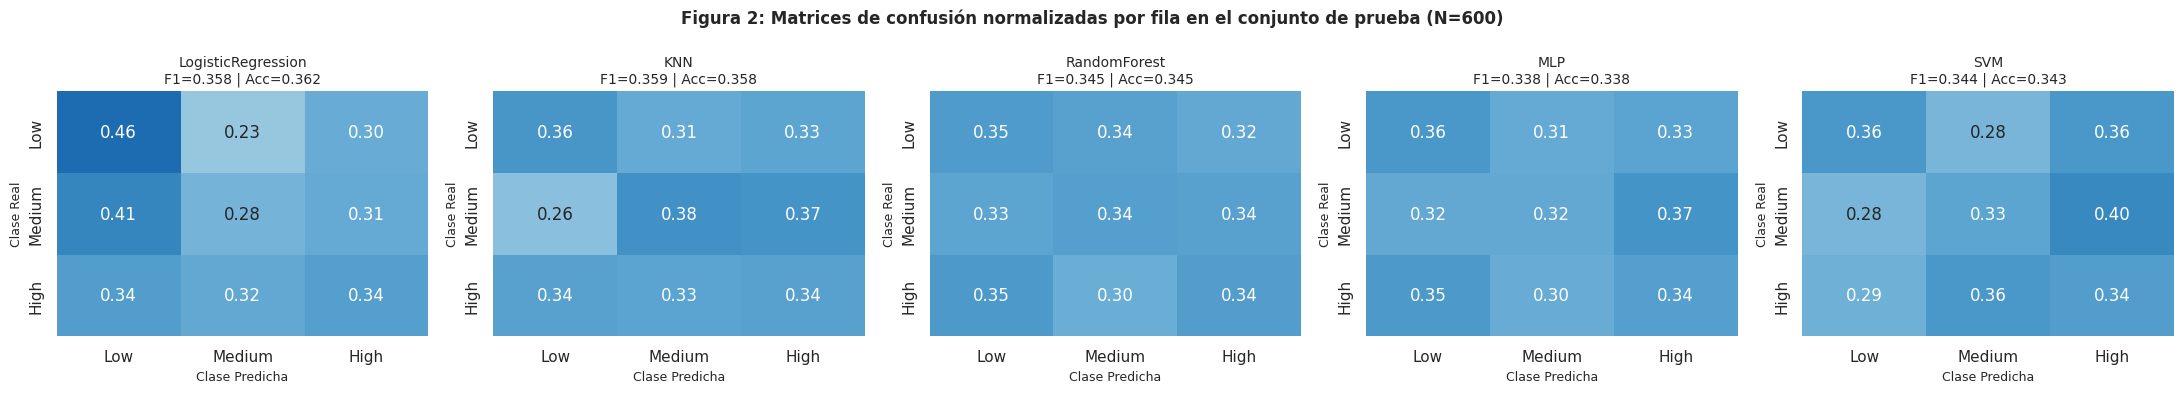

Figura 2 mostrada en el notebook.

=== Distribución de Predicciones en Prueba (N=600, 200 reales por clase) ===
LogisticRegression: Low=242 (40.3%), Medium=167 (27.8%), High=191 (31.8%)
KNN               : Low=191 (31.8%), Medium=203 (33.8%), High=206 (34.3%)
RandomForest      : Low=206 (34.3%), Medium=195 (32.5%), High=199 (33.2%)
MLP               : Low=206 (34.3%), Medium=186 (31.0%), High=208 (34.7%)
SVM               : Low=187 (31.2%), Medium=193 (32.2%), High=220 (36.7%)


In [23]:
# -----------------------------------------------------------------
# Generación de la Figura 2: Matrices de Confusión Normalizadas en Test
# -----------------------------------------------------------------
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
class_names = ['Low', 'Medium', 'High']

for idx, m_name in enumerate(experiment_log.keys()):
    cm = confusion_matrix(y_test, experiment_log[m_name]['pred_test'], normalize='true')
    sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', cbar=False,
                xticklabels=class_names, yticklabels=class_names, ax=axes[idx],
                vmin=0, vmax=0.6)
    test_m = experiment_log[m_name]['test']
    axes[idx].set_title(f'{m_name}\nF1={test_m["f1_macro"]:.3f} | Acc={test_m["accuracy"]:.3f}', fontsize=10)
    axes[idx].set_xlabel('Clase Predicha', fontsize=9)
    axes[idx].set_ylabel('Clase Real', fontsize=9)

plt.suptitle('Figura 2: Matrices de confusión normalizadas por fila en el conjunto de prueba (N=600)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()
print("Figura 2 mostrada en el notebook.")

# -----------------------------------------------------------------
# Distribución de predicciones por modelo en el conjunto de prueba (N=600)
# -----------------------------------------------------------------
print('\n=== Distribución de Predicciones en Prueba (N=600, 200 reales por clase) ===')
for m_name in experiment_log.keys():
    preds = experiment_log[m_name]['pred_test']
    counts = np.bincount(preds, minlength=3)
    props = counts / len(preds)
    print(f"{m_name:18}: Low={counts[0]:3d} ({props[0]*100:4.1f}%), "
          f"Medium={counts[1]:3d} ({props[1]*100:4.1f}%), "
          f"High={counts[2]:3d} ({props[2]*100:4.1f}%)")

#### Experimento de Sensibilidad a Estrategias de Gestión del Balance

Para evaluar rigurosamente la necesidad de técnicas de sobre/submuestreo, se contrastan en validación cruzada ($K=5$) con intervalos de confianza $t$ de Student las tres estrategias de balance sobre las 5 familias en sus hiperparámetros óptimos:
1. `'none'`: Modelo base sin re-muestreo ni ponderación.
2. `'class_weight'`: Ponderación analítica (`class_weight='balanced'`) en modelos compatibles (LogisticRegression, RandomForest, SVM).
3. `'random_oversample'`: Re-muestreo con reemplazo (`RandomOverSampler(random_state=42)`) aplicado de forma estricta exclusivamente en el entrenamiento interno de cada pliegue dentro de `run_cv`. Los resultados se presentan en la Tabla 3 y en la Figura 3. Dado que el dataset ya está balanceado, esperamos resultados idénticos entre estrategias; la capacidad real de las técnicas se muestra después en la prueba de estrés (Tabla 3B y Figura 3B).

Ejecutando experimento de sensibilidad...

Tabla 3: Experimento de sensibilidad a estrategias de balance de clases en validación cruzada (K=5, IC t-Student 95%)


,Modelo,Estrategia,Val F1-Macro (IC 95%),Val Accuracy
0,LogisticRegression,none,"0.3343 ± 0.0339 [0.3004, 0.3682]",0.3354
1,LogisticRegression,class_weight,"0.3343 ± 0.0339 [0.3004, 0.3682]",0.3354
2,LogisticRegression,random_oversample,"0.3343 ± 0.0339 [0.3004, 0.3682]",0.3354
3,KNN,none,"0.3369 ± 0.0191 [0.3178, 0.3559]",0.3379
4,KNN,random_oversample,"0.3369 ± 0.0191 [0.3178, 0.3559]",0.3379
5,RandomForest,none,"0.3423 ± 0.0228 [0.3195, 0.3651]",0.3429
6,RandomForest,class_weight,"0.3423 ± 0.0228 [0.3195, 0.3651]",0.3429
7,RandomForest,random_oversample,"0.3423 ± 0.0228 [0.3195, 0.3651]",0.3429
8,MLP,none,"0.3393 ± 0.0335 [0.3059, 0.3728]",0.3400
9,MLP,random_oversample,"0.3393 ± 0.0335 [0.3059, 0.3728]",0.3400


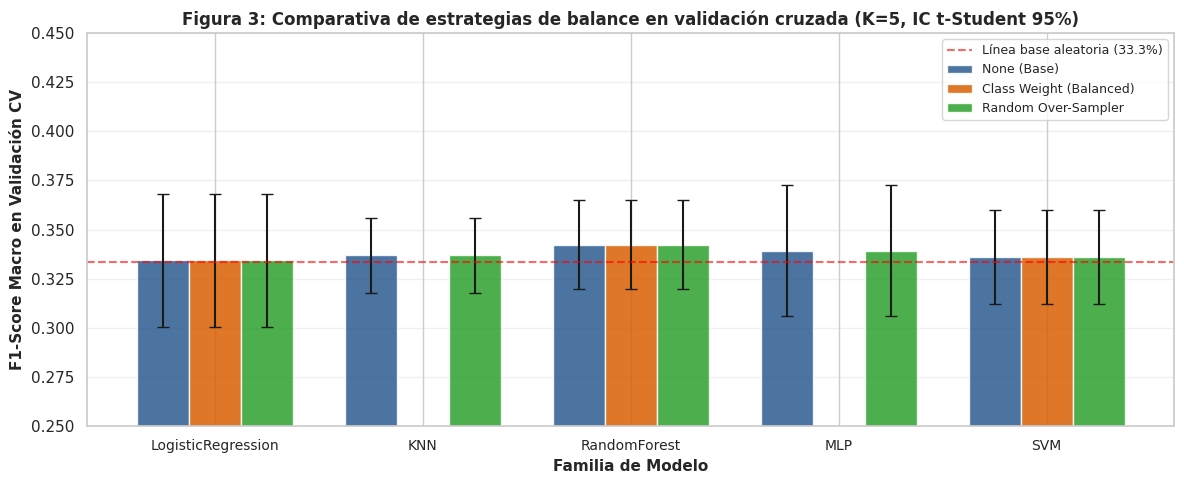

Figura 3 mostrada en el notebook.

=== Evaluación Algorítmica del Experimento de Sensibilidad ===
  • LogisticRegression: Diferencia máx F1 = 0.0000 | Solapamiento IC 95%: True
  • KNN               : Diferencia máx F1 = 0.0000 | Solapamiento IC 95%: True
  • RandomForest      : Diferencia máx F1 = 0.0000 | Solapamiento IC 95%: True
  • MLP               : Diferencia máx F1 = 0.0000 | Solapamiento IC 95%: True
  • SVM               : Diferencia máx F1 = 0.0000 | Solapamiento IC 95%: True

=== Conclusión Formal del Balance ===
→ Diagnóstico dinámico en pliegues de entrenamiento interno (K=5):
  IR real promedio = 1.0000 | Muestras por clase = 640 (total pliegue = 1920)
→ Solapamiento de IC 95% en todos los modelos evaluados: True
→ Conclusión metodológica: No existen diferencias estadísticamente distinguibles entre estrategias dentro del IC 95%.
  La discretización por terciles produce clases de tamaño casi idéntico (IR medio = 1.0000; ≈640 muestras
  por clase en el entrenamiento inter

In [24]:
# -----------------------------------------------------------------
# Experimento de Sensibilidad de Balance en Validación Cruzada (K=5)
# -----------------------------------------------------------------
ros = RandomOverSampler(random_state=42)

sens_results = []
print("Ejecutando experimento de sensibilidad...")

for m_name in experiment_log.keys():
    bp = experiment_log[m_name]['best_params']

    # 1. Estrategia 'none'
    tr_none, val_none = run_cv(lambda: build_model(m_name, bp), X_train_scaled, y_train, n_splits=5, seed=42, sampler=None)
    f1_none = val_none['f1_macro']
    sens_results.append({
        'Modelo': m_name, 'Estrategia': 'none',
        'Val F1-Macro Mean': f1_none['mean'], 'F1 Std': f1_none['std'], 't_crit': f1_none['t_crit'],
        'CI Low': f1_none['ci_low'], 'CI High': f1_none['ci_high'],
        'Val F1-Macro (IC 95%)': f"{f1_none['mean']:.4f} ± {f1_none['ci_high']-f1_none['mean']:.4f} [{f1_none['ci_low']:.4f}, {f1_none['ci_high']:.4f}]",
        'Val Accuracy': f"{val_none['accuracy']['mean']:.4f}"
    })

    # 2. Estrategia 'class_weight' (solo si el modelo lo admite)
    if m_name in SUPPORTS_CW:
        p_cw = {**bp, 'class_weight': 'balanced'}
        tr_cw, val_cw = run_cv(lambda p_c=p_cw: build_model(m_name, p_c), X_train_scaled, y_train, n_splits=5, seed=42, sampler=None)
        f1_cw = val_cw['f1_macro']
        sens_results.append({
            'Modelo': m_name, 'Estrategia': 'class_weight',
            'Val F1-Macro Mean': f1_cw['mean'], 'F1 Std': f1_cw['std'], 't_crit': f1_cw['t_crit'],
            'CI Low': f1_cw['ci_low'], 'CI High': f1_cw['ci_high'],
            'Val F1-Macro (IC 95%)': f"{f1_cw['mean']:.4f} ± {f1_cw['ci_high']-f1_cw['mean']:.4f} [{f1_cw['ci_low']:.4f}, {f1_cw['ci_high']:.4f}]",
            'Val Accuracy': f"{val_cw['accuracy']['mean']:.4f}"
        })

    # 3. Estrategia 'random_oversample' (aplica a todos)
    tr_ros, val_ros = run_cv(lambda: build_model(m_name, bp), X_train_scaled, y_train, n_splits=5, seed=42, sampler=ros)
    f1_ros = val_ros['f1_macro']
    sens_results.append({
        'Modelo': m_name, 'Estrategia': 'random_oversample',
        'Val F1-Macro Mean': f1_ros['mean'], 'F1 Std': f1_ros['std'], 't_crit': f1_ros['t_crit'],
        'CI Low': f1_ros['ci_low'], 'CI High': f1_ros['ci_high'],
        'Val F1-Macro (IC 95%)': f"{f1_ros['mean']:.4f} ± {f1_ros['ci_high']-f1_ros['mean']:.4f} [{f1_ros['ci_low']:.4f}, {f1_ros['ci_high']:.4f}]",
        'Val Accuracy': f"{val_ros['accuracy']['mean']:.4f}"
    })

df_sens = pd.DataFrame(sens_results)

print("\nTabla 3: Experimento de sensibilidad a estrategias de balance de clases en validación cruzada (K=5, IC t-Student 95%)")
display(df_sens[['Modelo', 'Estrategia', 'Val F1-Macro (IC 95%)', 'Val Accuracy']])

# -----------------------------------------------------------------
# Generación de la Figura 3: Gráfico de Sensibilidad
# -----------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 5))
models_order = list(experiment_log.keys())
strat_colors = {'none': '#2b5c8f', 'class_weight': '#d95f02', 'random_oversample': '#2ca02c'}
strat_labels = {'none': 'None (Base)', 'class_weight': 'Class Weight (Balanced)', 'random_oversample': 'Random Over-Sampler'}

x_base = np.arange(len(models_order))
width = 0.25

for s_idx, s_key in enumerate(['none', 'class_weight', 'random_oversample']):
    vals, errs = [], []
    for m in models_order:
        sub = df_sens[(df_sens['Modelo'] == m) & (df_sens['Estrategia'] == s_key)]
        if not sub.empty:
            mean = sub['Val F1-Macro Mean'].iloc[0]
            err = sub['CI High'].iloc[0] - mean
            vals.append(mean)
            errs.append(err)
        else:
            vals.append(0)
            errs.append(0)

    offset = (s_idx - 1) * width
    ax.bar(x_base + offset, vals, width, yerr=errs, capsize=4,
           label=strat_labels[s_key], color=strat_colors[s_key], alpha=0.85)

ax.axhline(y=1/3, color='red', linestyle='--', alpha=0.6, label='Línea base aleatoria (33.3%)')
ax.set_xticks(x_base)
ax.set_xticklabels(models_order, fontsize=10)
ax.set_xlabel('Familia de Modelo', fontsize=11, fontweight='bold')
ax.set_ylabel('F1-Score Macro en Validación CV', fontsize=11, fontweight='bold')
ax.set_title('Figura 3: Comparativa de estrategias de balance en validación cruzada (K=5, IC t-Student 95%)', fontsize=12, fontweight='bold')
ax.set_ylim(0.25, 0.45)
ax.legend(fontsize=9, loc='upper right')
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()
print("Figura 3 mostrada en el notebook.")

# -----------------------------------------------------------------
# Evaluación algorítmica y conclusión basada estrictamente en los datos
# -----------------------------------------------------------------
print('\n=== Evaluación Algorítmica del Experimento de Sensibilidad ===')
ci_overlap_by_model = {}
diff_max_by_model = {}

for m_name in experiment_log.keys():
    sub = df_sens[df_sens['Modelo'] == m_name]
    diff_max = sub['Val F1-Macro Mean'].max() - sub['Val F1-Macro Mean'].min()
    diff_max_by_model[m_name] = diff_max
    min_ci_high = sub['CI High'].min()
    max_ci_low  = sub['CI Low'].max()
    overlap = bool(max_ci_low <= min_ci_high)
    ci_overlap_by_model[m_name] = overlap
    print(f"  • {m_name:18}: Diferencia máx F1 = {diff_max:.4f} | Solapamiento IC 95%: {overlap}")

all_ci_overlap = all(ci_overlap_by_model.values())

# Cálculo aritmético exacto del IR y muestras en los pliegues de entrenamiento de CV
skf_sens = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
fold_irs = []
fold_n_per_class = []

for tr_i, val_i in skf_sens.split(X_train_scaled, y_train):
    bincnts = np.bincount(y_train[tr_i], minlength=3)
    ir_f = float(bincnts.max() / bincnts.min()) if bincnts.min() > 0 else np.inf
    fold_irs.append(ir_f)
    fold_n_per_class.append(bincnts)

mean_cv_ir = float(np.mean(fold_irs))
n_per_class_sample = fold_n_per_class[0][0]
total_tr_fold = sum(fold_n_per_class[0])

print('\n=== Conclusión Formal del Balance ===')
print(f'→ Diagnóstico dinámico en pliegues de entrenamiento interno (K=5):')
print(f'  IR real promedio = {mean_cv_ir:.4f} | Muestras por clase = {n_per_class_sample} (total pliegue = {total_tr_fold})')
print(f'→ Solapamiento de IC 95% en todos los modelos evaluados: {all_ci_overlap}')

if all_ci_overlap:
    print('→ Conclusión metodológica: No existen diferencias estadísticamente distinguibles entre estrategias dentro del IC 95%.')
    print(f'  La discretización por terciles produce clases de tamaño casi idéntico (IR medio = {mean_cv_ir:.4f}; ≈{n_per_class_sample} muestras')
    print('  por clase en el entrenamiento interno de cada pliegue), de modo que class_weight y random_oversample generan pesos ≈ unitarios')
    print('  y a lo sumo muy pocas muestras duplicadas, equivaliendo en la práctica a no aplicar tratamiento.')
else:
    non_overlap = [m for m, ov in ci_overlap_by_model.items() if not ov]
    print(f'→ Advertencia: Los siguientes modelos muestran diferencias fuera del IC 95%: {non_overlap}.')
    print('  Se recomienda revisar la tabla detallada de métricas para evaluar el impacto del balance.')

#### Prueba de Estrés: Gestión del Balance bajo Desbalance Controlado

El diagnóstico de la Parte I y de los pliegues de CV muestra clases perfectamente balanceadas (IR = 1.0), por lo que `BALANCE_STRATEGY = 'none'` y la Tabla 3 no distingue entre estrategias. Para verificar que el código gestiona el balance cuando hace falta, se submuestrea el entrenamiento a 800/400/160 muestras (Low/Medium/High, IR = 5.0) y se comparan, con los hiperparámetros óptimos de cada modelo, las estrategias `none`, `class_weight='balanced'`, `RandomOverSampler` y `RandomUnderSampler`. El remuestreo se ejecuta únicamente sobre el pliegue de entrenamiento y el conjunto de prueba permanece sellado. Como las clases de validación también quedan desbalanceadas, se reportan F1-macro y Balanced Accuracy (con IC $t$ de Student) y el recall por clase sobre las predicciones fuera de pliegue. Los resultados se presentan en la Tabla 3B y la Figura 3B.


=== Diagnóstico de Balance: Entrenamiento con desbalance artificial (prueba de estrés) ===
  Clase 0: 800 muestras (58.82%)
  Clase 1: 400 muestras (29.41%)
  Clase 2: 160 muestras (11.76%)
  Razón de desbalance (IR): 5.0000
  Veredicto: DESBALANCEADO (Criterio: IR <= 1.5 y |p_k - 1/3| <= 0.05)
  → Desbalance detectado: se requiere intervención en el muestreo.

Ejecutando prueba de estrés de balance (5 modelos x estrategias, K=5)...

Tabla 3B: Prueba de estrés de gestión del balance (entrenamiento con IR = 5.0; CV K=5, IC t-Student 95%; recall por clase sobre predicciones fuera de pliegue)


,Modelo,Estrategia,Val F1-Macro (IC 95%),Val Bal. Acc (IC 95%),Recall Low,Recall Medium,Recall High,% pred. High
0,LogisticRegression,none,"0.2469 [0.2469, 0.2469]","0.3333 [0.3333, 0.3333]",1.000,0.000,0.000,0.000
1,LogisticRegression,class_weight,"0.3035 [0.2776, 0.3293]","0.3408 [0.3000, 0.3817]",0.312,0.348,0.362,33.382
2,LogisticRegression,random_oversample,"0.3042 [0.2710, 0.3373]","0.3342 [0.2983, 0.3700]",0.328,0.350,0.325,33.235
3,LogisticRegression,random_undersample,"0.3008 [0.2770, 0.3246]","0.3438 [0.3040, 0.3835]",0.306,0.325,0.400,36.103
4,KNN,none,"0.2552 [0.2468, 0.2636]","0.3337 [0.3295, 0.3380]",0.986,0.015,0.000,0.000
5,KNN,random_oversample,"0.2892 [0.2479, 0.3306]","0.3175 [0.2751, 0.3599]",0.310,0.342,0.300,33.456
6,KNN,random_undersample,"0.3152 [0.2952, 0.3351]","0.3392 [0.3055, 0.3729]",0.350,0.392,0.275,29.632
7,RandomForest,none,"0.2902 [0.2748, 0.3056]","0.3396 [0.3297, 0.3494]",0.929,0.078,0.012,0.294
8,RandomForest,class_weight,"0.2933 [0.2643, 0.3224]","0.3383 [0.3160, 0.3607]",0.912,0.090,0.012,0.662
9,RandomForest,random_oversample,"0.3151 [0.3002, 0.3300]","0.3312 [0.3170, 0.3455]",0.779,0.178,0.038,3.750


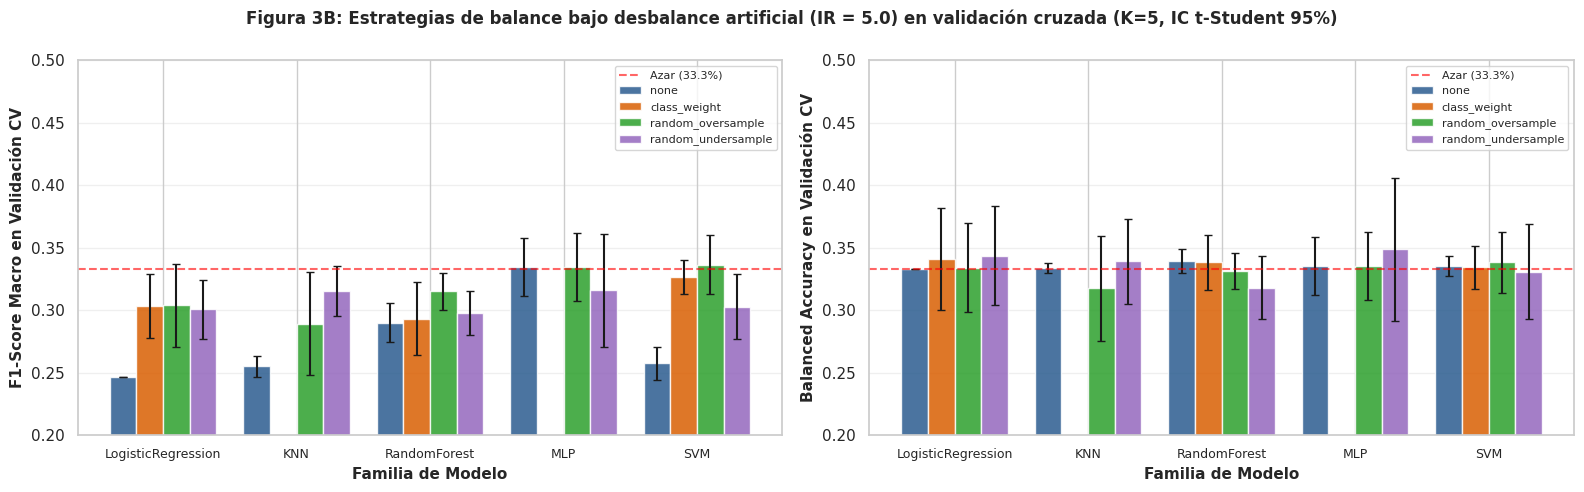

Figura 3B mostrada en el notebook.

=== Evaluación de la prueba de estrés ===
Recall medio de la clase minoritaria (High) por estrategia:
  none               : recall High = 0.019 | Balanced Acc media = 0.3357
  class_weight       : recall High = 0.192 | Balanced Acc media = 0.3379
  random_oversample  : recall High = 0.179 | Balanced Acc media = 0.3313
  random_undersample : recall High = 0.333 | Balanced Acc media = 0.3361
  • LogisticRegression: mejor estrategia = random_undersample  | ΔBalAcc vs none = +0.0104 | ΔRecall High = +0.400 | IC solapados (diferencia no distinguible)
  • KNN               : mejor estrategia = random_undersample  | ΔBalAcc vs none = +0.0054 | ΔRecall High = +0.275 | IC solapados (diferencia no distinguible)
  • RandomForest      : mejor estrategia = class_weight        | ΔBalAcc vs none = -0.0012 | ΔRecall High = +0.000 | IC solapados (diferencia no distinguible)
  • MLP               : mejor estrategia = random_undersample  | ΔBalAcc vs none = +0.0129 | 

In [25]:
# Prueba de estrés de gestión del balance (desbalance artificial SOLO en entrenamiento)
from imblearn.under_sampling import RandomUnderSampler
from sklearn.metrics import recall_score

# 1) Subconjunto de entrenamiento con desbalance controlado (IR = 5.0). Test y datos originales no se tocan.
rng_ib = np.random.RandomState(42)
target_counts = {0: 800, 1: 400, 2: 160}   # Low, Medium, High
keep_idx = np.sort(np.concatenate([
    rng_ib.choice(np.where(y_train == k)[0], size=n, replace=False)
    for k, n in target_counts.items()
]))
X_imb = X_train_scaled.iloc[keep_idx].reset_index(drop=True)
y_imb = y_train[keep_idx]
ir_imb, ok_imb = diagnose_balance(y_imb, name="Entrenamiento con desbalance artificial (prueba de estrés)")

# 2) Estrategias de gestión del balance (el remuestreo solo ve el pliegue de entrenamiento: anti-leakage)
stress_strategies = {
    'none':               lambda m: ({}, None),
    'class_weight':       lambda m: ({'class_weight': 'balanced'}, None) if m in SUPPORTS_CW else None,
    'random_oversample':  lambda m: ({}, RandomOverSampler(random_state=42)),
    'random_undersample': lambda m: ({}, RandomUnderSampler(random_state=42)),
}

def _ci95(v):
    v = np.asarray(v, dtype=float)
    m, s = v.mean(), v.std(ddof=1)
    h = stats.t.ppf(0.975, len(v) - 1) * s / np.sqrt(len(v))
    return m, m - h, m + h

def cv_stress(model_fn, X, y, sampler=None, n_splits=5, seed=42):
    """CV estratificada: F1-macro y Balanced Accuracy por pliegue (IC t-Student) + recall por clase sobre predicciones fuera de pliegue."""
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    f1s, bas, oof = [], [], np.zeros(len(y), dtype=int)
    for tr, va in skf.split(X, y):
        X_tr, y_tr = X.iloc[tr], y[tr]
        if sampler is not None:
            X_tr, y_tr = sampler.fit_resample(X_tr, y_tr)
        clf = model_fn()
        clf.fit(X_tr, y_tr)
        pred = clf.predict(X.iloc[va])
        oof[va] = pred
        f1s.append(f1_score(y[va], pred, average='macro', zero_division=0))
        bas.append(balanced_accuracy_score(y[va], pred))
    rec = recall_score(y, oof, labels=[0, 1, 2], average=None, zero_division=0)
    return _ci95(f1s), _ci95(bas), rec, np.bincount(oof, minlength=3) / len(oof)

stress_rows = []
print("Ejecutando prueba de estrés de balance (5 modelos x estrategias, K=5)...")
for m_name in experiment_log.keys():
    bp = experiment_log[m_name]['best_params']
    for s_name, factory in stress_strategies.items():
        cfg = factory(m_name)
        if cfg is None:
            continue
        extra, smp = cfg
        p_cfg = {**bp, **extra}
        (f1m, f1l, f1h), (bam, bal, bah), rec, share = cv_stress(
            lambda p_c=p_cfg: build_model(m_name, p_c), X_imb, y_imb, sampler=smp)
        stress_rows.append({
            'Modelo': m_name, 'Estrategia': s_name,
            'Val F1-Macro (IC 95%)': f"{f1m:.4f} [{f1l:.4f}, {f1h:.4f}]",
            'Val Bal. Acc (IC 95%)': f"{bam:.4f} [{bal:.4f}, {bah:.4f}]",
            'Recall Low': rec[0], 'Recall Medium': rec[1], 'Recall High': rec[2],
            '% pred. High': share[2] * 100,
            '_f1': f1m, '_f1_lo': f1l, '_f1_hi': f1h, '_ba': bam, '_ba_lo': bal, '_ba_hi': bah,
        })

df_stress = pd.DataFrame(stress_rows)
print("\nTabla 3B: Prueba de estrés de gestión del balance (entrenamiento con IR = 5.0; CV K=5, IC t-Student 95%; recall por clase sobre predicciones fuera de pliegue)")
display(df_stress[['Modelo', 'Estrategia', 'Val F1-Macro (IC 95%)', 'Val Bal. Acc (IC 95%)',
                   'Recall Low', 'Recall Medium', 'Recall High', '% pred. High']].round(3))

# 3) Figura 3B
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
models_order = list(experiment_log.keys())
strat_order = ['none', 'class_weight', 'random_oversample', 'random_undersample']
strat_colors2 = {'none': '#2b5c8f', 'class_weight': '#d95f02', 'random_oversample': '#2ca02c', 'random_undersample': '#9467bd'}
width2 = 0.2
for ax, (mk, lo, hi, ylab) in zip(axes, [('_f1', '_f1_lo', '_f1_hi', 'F1-Score Macro en Validación CV'),
                                          ('_ba', '_ba_lo', '_ba_hi', 'Balanced Accuracy en Validación CV')]):
    for s_idx, s_key in enumerate(strat_order):
        vals, errs = [], []
        for m in models_order:
            sub = df_stress[(df_stress['Modelo'] == m) & (df_stress['Estrategia'] == s_key)]
            if sub.empty:
                vals.append(0); errs.append(0)
            else:
                vals.append(sub[mk].iloc[0]); errs.append(sub[hi].iloc[0] - sub[mk].iloc[0])
        ax.bar(np.arange(len(models_order)) + (s_idx - 1.5) * width2, vals, width2, yerr=errs, capsize=3,
               label=s_key, color=strat_colors2[s_key], alpha=0.85)
    ax.axhline(y=1/3, color='red', linestyle='--', alpha=0.6, label='Azar (33.3%)')
    ax.set_xticks(np.arange(len(models_order))); ax.set_xticklabels(models_order, fontsize=9)
    ax.set_xlabel('Familia de Modelo', fontsize=11, fontweight='bold'); ax.set_ylabel(ylab, fontsize=11, fontweight='bold')
    ax.set_ylim(0.2, 0.5); ax.grid(True, alpha=0.3, axis='y'); ax.legend(fontsize=8, loc='upper right')
plt.suptitle('Figura 3B: Estrategias de balance bajo desbalance artificial (IR = 5.0) en validación cruzada (K=5, IC t-Student 95%)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()
print("Figura 3B mostrada en el notebook.")

# 4) Evaluación algorítmica
print("\n=== Evaluación de la prueba de estrés ===")
rec_high = df_stress.groupby('Estrategia')['Recall High'].mean().reindex(strat_order).dropna()
ba_mean = df_stress.groupby('Estrategia')['_ba'].mean().reindex(strat_order).dropna()
print("Recall medio de la clase minoritaria (High) por estrategia:")
for k, v in rec_high.items():
    print(f"  {k:19}: recall High = {v:.3f} | Balanced Acc media = {ba_mean[k]:.4f}")
for m in models_order:
    sub = df_stress[df_stress['Modelo'] == m]
    base = sub[sub['Estrategia'] == 'none'].iloc[0]
    others = sub[sub['Estrategia'] != 'none']
    best = others.loc[others['_ba'].idxmax()]
    sep = best['_ba_lo'] > base['_ba_hi']
    print(f"  • {m:18}: mejor estrategia = {best['Estrategia']:19} | ΔBalAcc vs none = {best['_ba'] - base['_ba']:+.4f} | "
          f"ΔRecall High = {best['Recall High'] - base['Recall High']:+.3f} | "
          f"{'IC separados' if sep else 'IC solapados (diferencia no distinguible)'}")
best_global = ba_mean.drop('none').idxmax()
print(f"\n→ Con desbalance, la estrategia con mayor Balanced Accuracy media es '{best_global}'; "
      f"la clase minoritaria pasa de recall {rec_high['none']:.3f} (none) a {rec_high[best_global]:.3f}.")
print("→ En el dataset real (IR = 1.0) BALANCE_STRATEGY = 'none' porque el balance proviene de la discretización por terciles;")
print("  si apareciera desbalance, la variable BALANCE_STRATEGY activaría automáticamente class_weight / sobremuestreo dentro de run_cv.")


In [26]:
# -----------------------------------------------------------------
# Análisis Crítico de Resultados Generado Dinámicamente desde Variables
# (Reemplazo programático de textos fijos en Sección 1.2)
# -----------------------------------------------------------------
print("=== Análisis de Desempeño y Cota Inferencial en t=0 ===")

for m_name in experiment_log.keys():
    v_ci = experiment_log[m_name]['best_val']['f1_macro']
    t_ci = experiment_log[m_name]['test_ci']['f1_macro']
    includes_random_val = (v_ci['ci_low'] <= 1/3 <= v_ci['ci_high'])
    includes_random_test = (t_ci[0] <= 1/3 <= t_ci[1])

    print(f"\nModelo: {m_name}")
    print(f"  • Val  F1-Macro = {v_ci['mean']:.4f} [{v_ci['ci_low']:.4f}, {v_ci['ci_high']:.4f}] → "
          f"{'Incluye baseline aleatorio (1/3)' if includes_random_val else 'Supera estadísticamente al azar'}")
    print(f"  • Test F1-Macro = {experiment_log[m_name]['test']['f1_macro']:.4f} [{t_ci[0]:.4f}, {t_ci[1]:.4f}] → "
          f"{'Incluye baseline aleatorio (1/3)' if includes_random_test else 'Supera estadísticamente al azar'}")

print("\n=== Conclusión de la Sección 1 ===")
print(f"1. Los dos mejores modelos seleccionados exclusivamente por validación cruzada son: {top2_models[0]} y {top2_models[1]}.")
_vm = {m: experiment_log[m]['best_val']['f1_macro'] for m in experiment_log}
_incl = [m for m, v in _vm.items() if v['ci_low'] <= 1/3 <= v['ci_high']]
_means = [v['mean'] for v in _vm.values()]
print(f"2. F1-macro medio de validación entre {min(_means)*100:.1f}% y {max(_means)*100:.1f}% (azar = 33.3%).")
if len(_incl) == len(_vm):
    print("   Los IC al 95% de los 5 modelos solapan con 1/3: las 8 variables antecedentes en t=0 aportan una señal predictiva muy sutil,")
    print("   insuficiente para una separación categórica robusta sin datos de resolución post-hoc.")
else:
    _exc = [m for m in _vm if m not in _incl]
    print(f"   Los IC al 95% de {_exc} excluyen 1/3 (señal por encima del azar); los de {_incl if _incl else 'ningún otro modelo'} solapan con 1/3.")
print("3. Se procede a la reducción de dimensión (Sección 2) evaluando si es posible simplificar la representación sin degradar este desempeño.")

=== Análisis de Desempeño y Cota Inferencial en t=0 ===

Modelo: LogisticRegression
  • Val  F1-Macro = 0.3343 [0.3004, 0.3682] → Incluye baseline aleatorio (1/3)
  • Test F1-Macro = 0.3582 [0.3238, 0.3971] → Incluye baseline aleatorio (1/3)

Modelo: KNN
  • Val  F1-Macro = 0.3369 [0.3178, 0.3559] → Incluye baseline aleatorio (1/3)
  • Test F1-Macro = 0.3586 [0.3228, 0.3948] → Incluye baseline aleatorio (1/3)

Modelo: RandomForest
  • Val  F1-Macro = 0.3423 [0.3195, 0.3651] → Incluye baseline aleatorio (1/3)
  • Test F1-Macro = 0.3450 [0.3065, 0.3844] → Incluye baseline aleatorio (1/3)

Modelo: MLP
  • Val  F1-Macro = 0.3393 [0.3059, 0.3728] → Incluye baseline aleatorio (1/3)
  • Test F1-Macro = 0.3381 [0.3020, 0.3791] → Incluye baseline aleatorio (1/3)

Modelo: SVM
  • Val  F1-Macro = 0.3361 [0.3123, 0.3599] → Incluye baseline aleatorio (1/3)
  • Test F1-Macro = 0.3438 [0.3053, 0.3830] → Incluye baseline aleatorio (1/3)

=== Conclusión de la Sección 1 ===
1. Los dos mejores modelos se

In [27]:
# Diagnóstico de la brecha entrenamiento-validación
print("=== Brecha entrenamiento-validación (diagnóstico de sobreajuste) ===")
gaps = {}
for m_name in experiment_log.keys():
    tr = experiment_log[m_name]['best_train']['f1_macro']['mean']
    va = experiment_log[m_name]['best_val']['f1_macro']['mean']
    gaps[m_name] = tr - va
    print(f"  {m_name:18}: Train F1 = {tr:.4f} | Val F1 = {va:.4f} | brecha = {tr - va:+.4f}")
overfit = [m for m, g in gaps.items() if g > 0.30]
if overfit:
    print(f"→ {overfit} ajustan casi perfectamente el entrenamiento (brecha > 0.30), pero ese ajuste no se traduce en validación.")
    print("  El F1 de entrenamiento no debe leerse como capacidad predictiva; la selección se basa solo en validación con IC.")
else:
    print("→ Ninguna brecha entrenamiento-validación supera 0.30.")


=== Brecha entrenamiento-validación (diagnóstico de sobreajuste) ===
  LogisticRegression: Train F1 = 0.3911 | Val F1 = 0.3343 | brecha = +0.0568
  KNN               : Train F1 = 1.0000 | Val F1 = 0.3369 | brecha = +0.6631
  RandomForest      : Train F1 = 1.0000 | Val F1 = 0.3423 | brecha = +0.6577
  MLP               : Train F1 = 1.0000 | Val F1 = 0.3393 | brecha = +0.6607
  SVM               : Train F1 = 0.6489 | Val F1 = 0.3361 | brecha = +0.3128
→ ['KNN', 'RandomForest', 'MLP', 'SVM'] ajustan casi perfectamente el entrenamiento (brecha > 0.30), pero ese ajuste no se traduce en validación.
  El F1 de entrenamiento no debe leerse como capacidad predictiva; la selección se basa solo en validación con IC.


## Sección 2: Reducción de Dimensión (20%)

### 2.1 Análisis Individual de Cada Característica

Antes de proyectar el espacio antecedente a dimensiones latentes, se evalúa la capacidad discriminativa individual de las $D=32$ variables respecto a la severidad sobre el conjunto de entrenamiento estandarizado ($X_{\text{train\_scaled}}$), garantizando la ausencia de fuga estadística hacia el conjunto de prueba.

Se emplean dos criterios complementarios:
1. **ANOVA $F$-Statistic (`f_classif`):** Evalúa la separación lineal de medias condicionales entre clases respecto a la varianza intraclasal. El umbral crítico correspondiente a un nivel de significancia de $p = 0.15$ se calcula formalmente a partir de la distribución de Fisher:
   $$F_{\text{crit}} = \text{scipy.stats.f.ppf}(1 - 0.15, \, df_1 = 2, \, df_2 = N_{\text{train}} - 3)$$
2. **Información Mutua (`mutual_info_classif`):** Cuantifica la dependencia probabilística total (lineal y no lineal) entre cada predictor $X_j$ e $Y$. Se especifica explícitamente una máscara booleana (`discrete_features`) para tratar las variables ficticias binarias de One-Hot como discretas y las variables numéricas estandarizadas (`Year`, `Number of Affected Users`) como continuas, con semilla `random_state=42`.

**Criterio de Candidatas a Eliminación:**  
Una característica se considera candidata formal a eliminación si satisface simultáneamente:
$$p\text{-valor ANOVA} > 0.15 \quad \text{AND} \quad \text{Información Mutua} \le 0.005 \text{ nats}$$

Los resultados se presentan en la Tabla 4 (valores por variable y decisión) y en la Figura 4 (ranking de las 15 variables con mayor capacidad discriminativa).

Tabla 4: Capacidad discriminativa individual de las D variables antecedente sobre el conjunto de entrenamiento


,Feature,ANOVA_F,p_value,Mutual_Info,Decision
0,Country_India,2.837355,0.058777,0.001151,Conservar
1,Security Vulnerability Type_Unpatched Software,2.772891,0.062682,0.001169,Conservar
2,Attack Source_Insider,2.608287,0.073870,0.001077,Conservar
3,Security Vulnerability Type_Weak Passwords,2.212916,0.109605,0.000913,Conservar
4,Target Industry_Government,1.873844,0.153757,0.000795,Candidata a eliminar
5,Target Industry_Education,1.872608,0.153947,0.000779,Candidata a eliminar
6,Attack Type_Ransomware,1.789590,0.167252,0.000735,Candidata a eliminar
7,Defense Mechanism Used_Firewall,1.592521,0.203627,0.000661,Candidata a eliminar
8,Country_Brazil,1.272393,0.280349,0.000538,Candidata a eliminar
9,Number of Affected Users,1.242706,0.288788,0.000000,Candidata a eliminar



=== Resumen de Selección Individual ===
• Umbral crítico F (p=0.15, df1=2, df2=2397): F_crit = 1.8986
• Características evaluadas: 32
• Características a conservar: 5
• Características candidatas a eliminación (p > 0.15 AND MI <= 0.005): 27
• Características con ANOVA significativo (p <= 0.15, equivalente a F >= F_crit): 4 de 32
• Lista de características candidatas a ser eliminadas:


,Feature,ANOVA_F,p_value,Mutual_Info
0,Target Industry_Government,1.873844,0.153757,0.000795
1,Target Industry_Education,1.872608,0.153947,0.000779
2,Attack Type_Ransomware,1.789590,0.167252,0.000735
3,Defense Mechanism Used_Firewall,1.592521,0.203627,0.000661
4,Country_Brazil,1.272393,0.280349,0.000538
5,Number of Affected Users,1.242706,0.288788,0.000000
6,Target Industry_Telecommunications,0.858657,0.423861,0.000355
7,Attack Source_Nation-state,0.727470,0.483236,0.000302
8,Country_Germany,0.714296,0.489641,0.000293
9,Country_France,0.682193,0.505605,0.000286


• Top 5 por ANOVA F: ['Country_India', 'Security Vulnerability Type_Unpatched Software', 'Attack Source_Insider', 'Security Vulnerability Type_Weak Passwords', 'Target Industry_Government']
• Top 5 por Información Mutua: ['Year', 'Security Vulnerability Type_Unpatched Software', 'Country_India', 'Attack Source_Insider', 'Security Vulnerability Type_Weak Passwords']


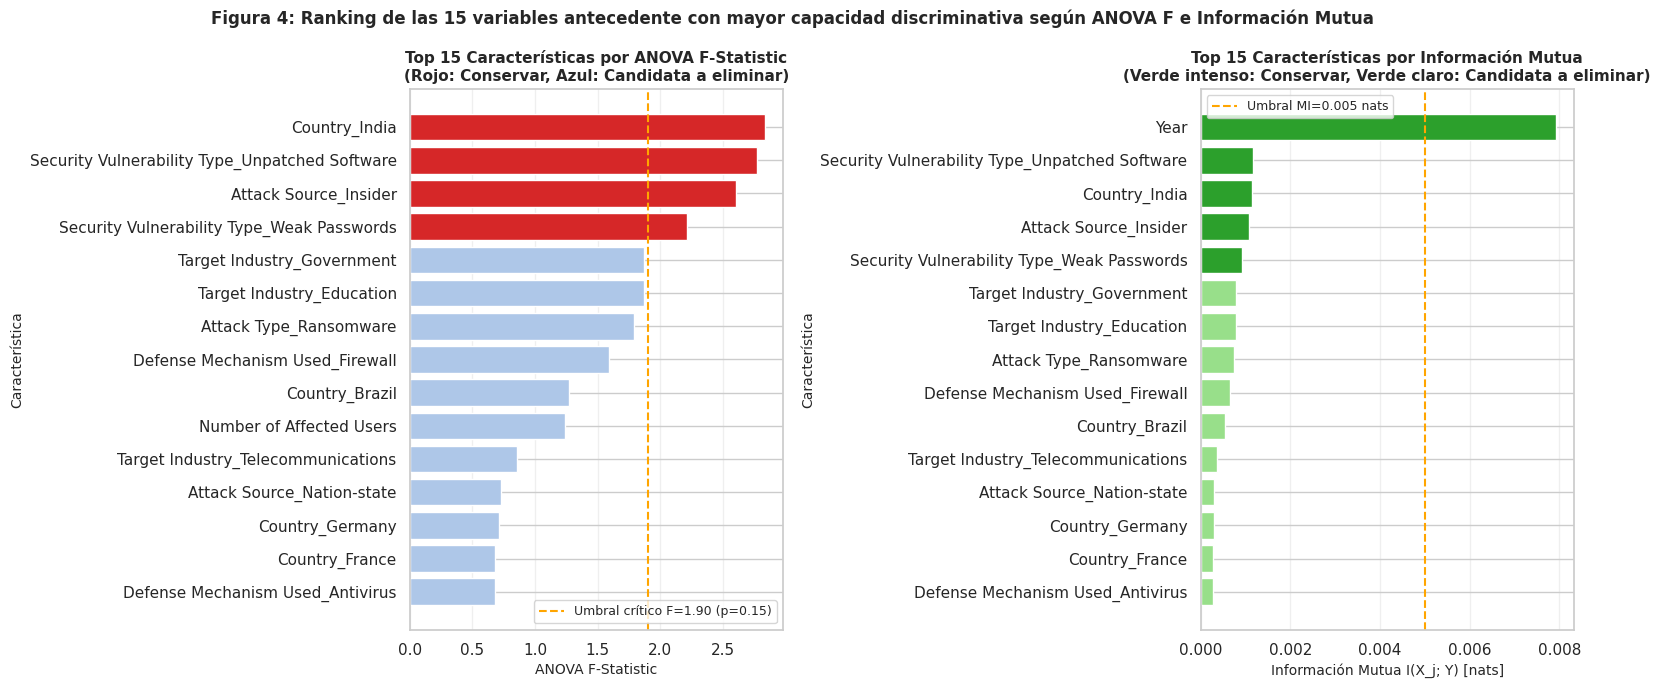

Figura 4 mostrada en el notebook.


In [28]:
from sklearn.feature_selection import f_classif, mutual_info_classif

# -----------------------------------------------------------------
# Análisis Individual de Capacidad Discriminativa (ANOVA F e Info Mutua)
# -----------------------------------------------------------------
P_THRESHOLD = 0.15
MI_THRESHOLD = 0.005

N_tr = len(X_train_scaled)
f_crit = float(stats.f.ppf(1 - P_THRESHOLD, dfn=2, dfd=N_tr - 3))

# Máscara booleana para información mutua: True para dummies discretas, False para numéricas continuas
discrete_mask = [col not in num_scale_cols for col in feature_names]

f_vals, p_vals = f_classif(X_train_scaled, y_train)
mi_vals = mutual_info_classif(X_train_scaled, y_train, discrete_features=discrete_mask, random_state=42)

feature_df = pd.DataFrame({
    'Feature': feature_names,
    'ANOVA_F': f_vals,
    'p_value': p_vals,
    'Mutual_Info': mi_vals
})

feature_df['Decision'] = np.where(
    (feature_df['p_value'] > P_THRESHOLD) & (feature_df['Mutual_Info'] <= MI_THRESHOLD),
    'Candidata a eliminar', 'Conservar'
)

feature_df = feature_df.sort_values('ANOVA_F', ascending=False).reset_index(drop=True)

candidates = feature_df[feature_df['Decision'] == 'Candidata a eliminar']['Feature'].tolist()
n_candidates = len(candidates)
n_retain = len(feature_df) - n_candidates

print("Tabla 4: Capacidad discriminativa individual de las D variables antecedente sobre el conjunto de entrenamiento")
display(feature_df)

print(f"\n=== Resumen de Selección Individual ===")
print(f"• Umbral crítico F (p=0.15, df1=2, df2={N_tr-3}): F_crit = {f_crit:.4f}")
print(f"• Características evaluadas: {len(feature_df)}")
print(f"• Características a conservar: {n_retain}")
print(f"• Características candidatas a eliminación (p > {P_THRESHOLD} AND MI <= {MI_THRESHOLD}): {n_candidates}")
n_sig = int((feature_df['p_value'] <= P_THRESHOLD).sum())
print(f"• Características con ANOVA significativo (p <= {P_THRESHOLD}, equivalente a F >= F_crit): {n_sig} de {len(feature_df)}")
if n_candidates > 0:
    print("• Lista de características candidatas a ser eliminadas:")
    display(feature_df[feature_df['Decision'] == 'Candidata a eliminar'][['Feature', 'ANOVA_F', 'p_value', 'Mutual_Info']].reset_index(drop=True))
else:
    print(f"• Ninguna característica cumple simultáneamente ambos criterios: no hay candidatas a eliminar; se conservan las {len(feature_df)}.")
print("• Top 5 por ANOVA F:", feature_df.sort_values('ANOVA_F', ascending=False)['Feature'].head(5).tolist())
print("• Top 5 por Información Mutua:", feature_df.sort_values('Mutual_Info', ascending=False)['Feature'].head(5).tolist())

# -----------------------------------------------------------------
# Generación de la Figura 4: Capacidad Discriminativa Top 15
# -----------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# (Izquierda) Top 15 por ANOVA F
top_anova = feature_df.sort_values('ANOVA_F', ascending=True).tail(15)
colors_anova = ['#d62728' if f not in candidates else '#aec7e8' for f in top_anova['Feature']]
axes[0].barh(top_anova['Feature'], top_anova['ANOVA_F'], color=colors_anova, edgecolor='white')
axes[0].axvline(x=f_crit, color='orange', linestyle='--', linewidth=1.5, label=f'Umbral crítico F={f_crit:.2f} (p=0.15)')
axes[0].set_title('Top 15 Características por ANOVA F-Statistic\n(Rojo: Conservar, Azul: Candidata a eliminar)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('ANOVA F-Statistic', fontsize=10); axes[0].set_ylabel('Característica', fontsize=10); axes[0].legend(fontsize=9); axes[0].grid(True, alpha=0.3, axis='x')

# (Derecha) Top 15 por Información Mutua
top_mi = feature_df.sort_values('Mutual_Info', ascending=True).tail(15)
colors_mi = ['#2ca02c' if f not in candidates else '#98df8a' for f in top_mi['Feature']]
axes[1].barh(top_mi['Feature'], top_mi['Mutual_Info'], color=colors_mi, edgecolor='white')
axes[1].axvline(x=MI_THRESHOLD, color='orange', linestyle='--', linewidth=1.5, label=f'Umbral MI={MI_THRESHOLD} nats')
axes[1].set_title('Top 15 Características por Información Mutua\n(Verde intenso: Conservar, Verde claro: Candidata a eliminar)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Información Mutua I(X_j; Y) [nats]', fontsize=10); axes[1].set_ylabel('Característica', fontsize=10); axes[1].legend(fontsize=9); axes[1].grid(True, alpha=0.3, axis='x')

plt.suptitle('Figura 4: Ranking de las 15 variables antecedente con mayor capacidad discriminativa según ANOVA F e Información Mutua',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()
print("Figura 4 mostrada en el notebook.")

#### Interpretación de la Tabla 4: corrección por pruebas múltiples

Como se evalúan $D=32$ pruebas ANOVA de forma simultánea, con un umbral de $p=0.15$ se esperan falsos positivos solo por azar (aproximadamente $D \cdot 0.15$). La celda siguiente contrasta el número de variables significativas observadas con ese valor esperado y aplica la corrección de Bonferroni para responder si existen candidatas a eliminar y cuáles son.


In [29]:
# Contraste de múltiples pruebas sobre el ANOVA individual (Tabla 4)
m_tests = len(feature_df)
bonf_alpha = 0.05 / m_tests
n_bonf = int((feature_df['p_value'] <= bonf_alpha).sum())
n_sig_raw = int((feature_df['p_value'] <= P_THRESHOLD).sum())
expected_fp = m_tests * P_THRESHOLD
print(f"• Pruebas ANOVA realizadas: {m_tests}")
print(f"• Significativas con p <= {P_THRESHOLD}: {n_sig_raw} observadas vs {expected_fp:.1f} esperadas solo por azar bajo H0 (m·p)")
print(f"• Significativas tras corrección de Bonferroni (p <= {bonf_alpha:.4f}): {n_bonf}")
mi_only = feature_df[(feature_df['p_value'] > P_THRESHOLD) & (feature_df['Mutual_Info'] > MI_THRESHOLD)]['Feature'].tolist()
if mi_only:
    print(f"• Conservadas solo por Información Mutua (ANOVA no significativo): {mi_only}")
    print(f"  La MI de variables numéricas se estima con vecinos más cercanos y es ruidosa con efectos tan pequeños; "
          f"'Year' toma solo {X_train_scaled['Year'].nunique()} valores distintos.")
if n_bonf == 0:
    print("→ Ninguna variable es individualmente discriminativa tras la corrección por pruebas múltiples, y el número de significativas sin corregir")
    print("  es comparable al esperado por azar: no hay evidencia sólida de variables con capacidad discriminativa individual,")
    print("  coherente con el desempeño de los clasificadores. Las candidatas a eliminar son, por tanto, la gran mayoría de las variables.")
else:
    print(f"→ {n_bonf} variable(s) sobreviven a la corrección de Bonferroni y deben conservarse.")


• Pruebas ANOVA realizadas: 32
• Significativas con p <= 0.15: 4 observadas vs 4.8 esperadas solo por azar bajo H0 (m·p)
• Significativas tras corrección de Bonferroni (p <= 0.0016): 0
• Conservadas solo por Información Mutua (ANOVA no significativo): ['Year']
  La MI de variables numéricas se estima con vecinos más cercanos y es ruidosa con efectos tan pequeños; 'Year' toma solo 10 valores distintos.
→ Ninguna variable es individualmente discriminativa tras la corrección por pruebas múltiples, y el número de significativas sin corregir
  es comparable al esperado por azar: no hay evidencia sólida de variables con capacidad discriminativa individual,
  coherente con el desempeño de los clasificadores. Las candidatas a eliminar son, por tanto, la gran mayoría de las variables.


### 2.2 Extracción Lineal de Características: PCA

**Criterio de Selección:**  
Se aplica Análisis de Componentes Principales (PCA) fijando como criterio la retención de al menos el **$90\%$ de la varianza total acumulada** ($\eta(K) \ge 0.90$). Este umbral garantiza preservar la estructura ortogonal dominante de dispersión del dataset antecedente, descartando las direcciones de menor inercia asociadas a ruido o redundancia de codificación One-Hot.

**Protocolo Estricto Anti-Fuga (*Anti-Leakage*):**  
Para evitar cualquier filtración de información estadística:
1. En validación cruzada ($K=5$), PCA se encapsula dentro de un `Pipeline([('pca', PCA(n_components=0.90, svd_solver='full', random_state=42)), ('clf', build_model(...))])`, de manera que el ajuste de vectores propios ocurre **estrictamente en el pliegue de entrenamiento interno** ($X_{tr}$) y solo se proyecta sobre el pliegue de validación ($X_{val}$).
2. Para la evaluación final en prueba, PCA se ajusta exclusivamente sobre el conjunto de entrenamiento completo ($X_{\text{train\_scaled}}$) y se transforma el conjunto de prueba ($X_{\text{test\_scaled}}$).

La Figura 5 muestra la curva de varianza explicada acumulada y la Tabla 5 compara, para los dos mejores modelos, el espacio original con el espacio PCA (porcentaje de reducción y demás métricas).

Dimensión original: D = 32
Componentes requeridos para >= 90% varianza: K = 22
Varianza explicada acumulada retenida: 90.11%
Porcentaje de compresión dimensional: 31.25%


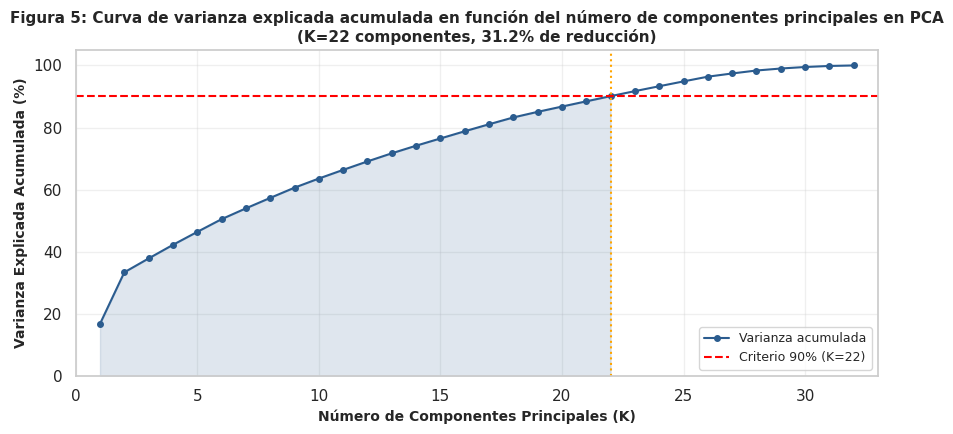

Figura 5 mostrada en el notebook.
Tabla 5: Comparativa de desempeño entre el espacio original y el espacio reducido por PCA (var >= 90%) para los dos mejores modelos


,Modelo,Espacio,N° Comp,% Reducción,Train F1,Val F1 (IC 95%),Test F1 [IC95%],Test Accuracy,Test Bal. Acc,Test ROC-AUC
0,RandomForest,Original (D=32),32,0.00%,1.0000,"0.3423 [0.3195, 0.3651]","0.3450 [0.3065, 0.3844]",0.3450,0.3450,0.5043
1,RandomForest,PCA (K=22),22,31.2%,1.0000,"0.3359 [0.3175, 0.3543]","0.3400 [0.3017, 0.3802]",0.3400,0.3400,0.4907
2,MLP,Original (D=32),32,0.00%,1.0000,"0.3393 [0.3059, 0.3728]","0.3381 [0.3020, 0.3791]",0.3383,0.3383,0.5128
3,MLP,PCA (K=22),22,31.2%,0.9979,"0.3266 [0.3063, 0.3468]","0.3225 [0.2819, 0.3578]",0.3233,0.3233,0.4946


In [30]:
from sklearn.decomposition import PCA
# -----------------------------------------------------------------
# Extracción Lineal mediante PCA (Criterio Varianza >= 90%)
# -----------------------------------------------------------------
pca_full = PCA(svd_solver='full', random_state=42).fit(X_train_scaled)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
k_pca = int(np.argmax(cum_var >= 0.90) + 1)
pct_red_pca = (1.0 - (k_pca / D)) * 100

print(f"Dimensión original: D = {D}")
print(f"Componentes requeridos para >= 90% varianza: K = {k_pca}")
print(f"Varianza explicada acumulada retenida: {cum_var[k_pca-1]*100:.2f}%")
print(f"Porcentaje de compresión dimensional: {pct_red_pca:.2f}%")

# -----------------------------------------------------------------
# Generación de la Figura 5: Curva de Varianza Acumulada
# -----------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 4.5))
comp_range = np.arange(1, D + 1)
ax.plot(comp_range, cum_var * 100, 'o-', color='#2b5c8f', markersize=4, linewidth=1.5, label='Varianza acumulada')
ax.axhline(y=90, color='red', linestyle='--', linewidth=1.5, label=f'Criterio 90% (K={k_pca})')
ax.axvline(x=k_pca, color='orange', linestyle=':', linewidth=1.5)
ax.fill_between(comp_range[:k_pca], cum_var[:k_pca] * 100, alpha=0.15, color='#2b5c8f')
ax.set_xlabel('Número de Componentes Principales (K)', fontsize=10, fontweight='bold')
ax.set_ylabel('Varianza Explicada Acumulada (%)', fontsize=10, fontweight='bold')
ax.set_title(f'Figura 5: Curva de varianza explicada acumulada en función del número de componentes principales en PCA\n(K={k_pca} componentes, {pct_red_pca:.1f}% de reducción)', fontsize=11, fontweight='bold')
ax.set_xlim(0, D + 1); ax.set_ylim(0, 105); ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print("Figura 5 mostrada en el notebook.")

# -----------------------------------------------------------------
# Reevaluación de los dos mejores modelos con Pipeline en CV y Test
# -----------------------------------------------------------------
from sklearn.pipeline import Pipeline

pca_results = []
pca_test_models = {}

# Ajuste global de PCA para Test
pca_fit_global = PCA(n_components=k_pca, svd_solver='full', random_state=42)
X_tr_pca = pca_fit_global.fit_transform(X_train_scaled)
X_te_pca = pca_fit_global.transform(X_test_scaled)

for m_name in top2_models:
    bp = experiment_log[m_name]['best_params']
    cw, smp = balance_for(m_name)

    # Validación cruzada rigurosa con Pipeline (anti-leakage)
    tr_pca_cv, val_pca_cv = run_cv(
        lambda: Pipeline([
            ('pca', PCA(n_components=k_pca, svd_solver='full', random_state=42)),
            ('clf', build_model(m_name, bp))
        ]),
        X_train_scaled, y_train, n_splits=5, seed=42, sampler=smp
    )

    # Ajuste final sobre X_tr_pca y prueba en X_te_pca
    X_tr_fit_pca, y_tr_fit_pca = smp.fit_resample(X_tr_pca, y_train) if smp is not None else (X_tr_pca, y_train)
    clf_pca = build_model(m_name, bp)
    clf_pca.fit(X_tr_fit_pca, y_tr_fit_pca)

    pred_te_pca = clf_pca.predict(X_te_pca)
    proba_te_pca = clf_pca.predict_proba(X_te_pca) if hasattr(clf_pca, 'predict_proba') else None

    pca_test_m = evaluate_metrics(y_test, pred_te_pca, proba_te_pca)
    pca_boot = bootstrap_test_metrics(y_test, pred_te_pca, proba_te_pca, n_boot=1000, seed=42)

    pca_test_models[m_name] = {'clf': clf_pca, 'test': pca_test_m, 'test_ci': pca_boot, 'val': val_pca_cv, 'train': tr_pca_cv}

    # Comparativa fila a fila
    orig_val = experiment_log[m_name]['best_val']['f1_macro']
    orig_test = experiment_log[m_name]['test']
    orig_ci = experiment_log[m_name]['test_ci']['f1_macro']

    val_f1_p = val_pca_cv['f1_macro']

    pca_results.extend([
        {
            'Modelo': m_name, 'Espacio': f'Original (D={D})', 'N° Comp': D, '% Reducción': '0.00%',
            'Train F1': f"{experiment_log[m_name]['best_train']['f1_macro']['mean']:.4f}",
            'Val F1 (IC 95%)': f"{orig_val['mean']:.4f} [{orig_val['ci_low']:.4f}, {orig_val['ci_high']:.4f}]",
            'Test F1 [IC95%]': f"{orig_test['f1_macro']:.4f} [{orig_ci[0]:.4f}, {orig_ci[1]:.4f}]",
            'Test Accuracy': f"{orig_test['accuracy']:.4f}",
            'Test Bal. Acc': f"{orig_test['balanced_accuracy']:.4f}",
            'Test ROC-AUC': f"{orig_test['roc_auc_macro']:.4f}" if orig_test['roc_auc_macro'] else "N/A"
        },
        {
            'Modelo': m_name, 'Espacio': f'PCA (K={k_pca})', 'N° Comp': k_pca, '% Reducción': f"{pct_red_pca:.1f}%",
            'Train F1': f"{tr_pca_cv['f1_macro']['mean']:.4f}",
            'Val F1 (IC 95%)': f"{val_f1_p['mean']:.4f} [{val_f1_p['ci_low']:.4f}, {val_f1_p['ci_high']:.4f}]",
            'Test F1 [IC95%]': f"{pca_test_m['f1_macro']:.4f} [{pca_boot['f1_macro'][0]:.4f}, {pca_boot['f1_macro'][1]:.4f}]",
            'Test Accuracy': f"{pca_test_m['accuracy']:.4f}",
            'Test Bal. Acc': f"{pca_test_m['balanced_accuracy']:.4f}",
            'Test ROC-AUC': f"{pca_test_m['roc_auc_macro']:.4f}" if pca_test_m['roc_auc_macro'] else "N/A"
        }
    ])

df_tabla5 = pd.DataFrame(pca_results)

print("Tabla 5: Comparativa de desempeño entre el espacio original y el espacio reducido por PCA (var >= 90%) para los dos mejores modelos")
display(df_tabla5)

### 2.3.A Extracción No Lineal de Características: UMAP

**Criterio de Selección de Componentes Latentes ($K$):**  
UMAP (*Uniform Manifold Approximation and Projection*) modela la geometría de variedades Riemannianas no lineales de los datos. Para determinar el número óptimo de componentes latentes $K$, se evalúa la malla $K \in \{2, 3, 5, 10, 15\}$ (con hiperparámetros fijos `n_neighbors=15, min_dist=0.1, random_state=42`) mediante validación cruzada con `Pipeline` estricto ajustado solo en entrenamiento de cada pliegue. Como ambos modelos comparten el mismo espacio latente, se adopta el menor $K$ admisible simultáneamente para los dos (si no existe, el del mejor modelo).

Siguiendo el **principio de parsimonia estadística**, se selecciona el valor más pequeño de $K$ cuyo F1-Score Macro de validación se encuentre contenido dentro del intervalo de confianza al 95% del mejor desempeño alcanzado en la malla. Esto maximiza la tasa de compresión y eficiencia computacional sin incurrir en pérdidas estadísticamente discernibles.

**Protocolo Anti-Fuga:**  
Con el $K$ seleccionado, UMAP se ajusta exclusivamente en el conjunto de entrenamiento ($X_{\text{train\_scaled}}$) y se transforma el conjunto de prueba ($X_{\text{test\_scaled}}$). Para visualización 2D, se ajusta un proyector UMAP con $K=2$ sobre Train y se proyecta Test.

La Figura 6 presenta la selección de $K$ y la proyección 2D, y la Tabla 6 compara el espacio original con el espacio UMAP (porcentaje de reducción y demás métricas).

Evaluando K en UMAP con validación cruzada para los dos mejores modelos...
  RandomForest (K= 2): Val F1 = 0.3308 [0.3128, 0.3487]
  RandomForest (K= 3): Val F1 = 0.3344 [0.3041, 0.3648]
  RandomForest (K= 5): Val F1 = 0.3362 [0.3026, 0.3697]
  RandomForest (K=10): Val F1 = 0.3387 [0.2937, 0.3838]
  RandomForest (K=15): Val F1 = 0.3321 [0.2949, 0.3693]
  MLP (K= 2): Val F1 = 0.3333 [0.3014, 0.3651]
  MLP (K= 3): Val F1 = 0.3250 [0.2948, 0.3553]
  MLP (K= 5): Val F1 = 0.3347 [0.3021, 0.3673]
  MLP (K=10): Val F1 = 0.3385 [0.2962, 0.3809]
  MLP (K=15): Val F1 = 0.3296 [0.2955, 0.3637]
→ K óptimo por parsimonia para RandomForest: K = 2 (Mejor K=10)
→ K óptimo por parsimonia para MLP: K = 2 (Mejor K=10)
→ K común elegido (menor K admisible simultáneamente para los dos modelos): K = 2
Ajustando UMAP 2D sobre Train y proyectando Test para visualización...


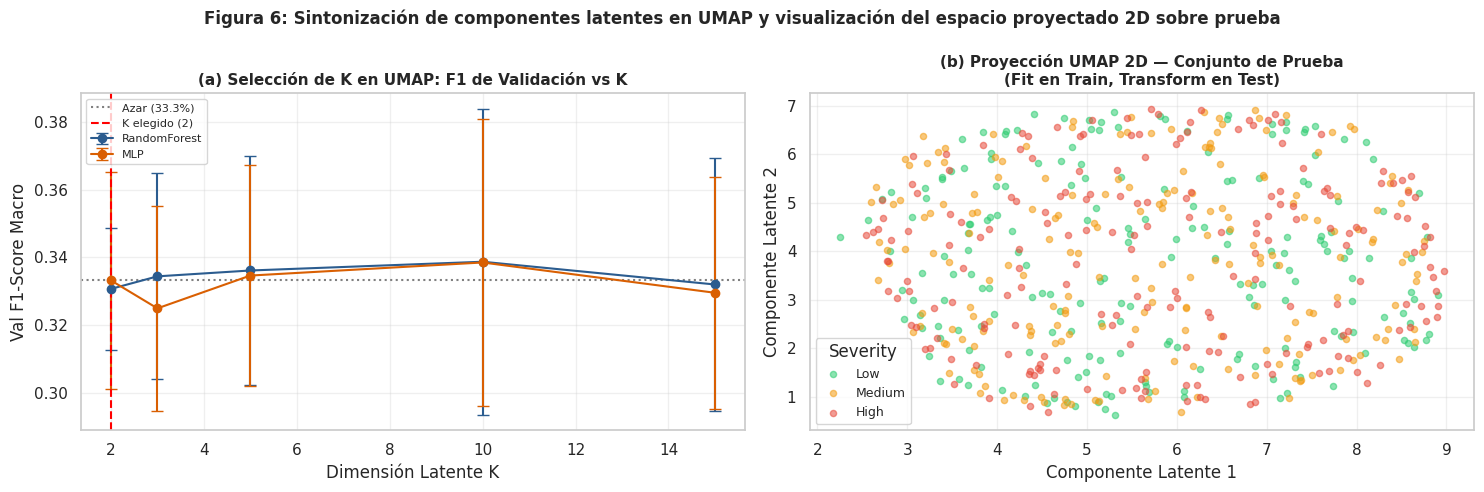

Figura 6 mostrada en el notebook.
Tabla 6: Comparativa de desempeño entre el espacio original y el espacio latente UMAP para los dos mejores modelos


,Modelo,Espacio,N° Comp,% Reducción,Train F1,Val F1 (IC 95%),Test F1 [IC95%],Test Accuracy,Test Bal. Acc,Test ROC-AUC
0,RandomForest,Original (D=32),32,0.00%,1.0000,"0.3423 [0.3195, 0.3651]","0.3450 [0.3065, 0.3844]",0.3450,0.3450,0.5043
1,RandomForest,UMAP (K=2),2,93.8%,1.0000,"0.3308 [0.3128, 0.3487]","0.3171 [0.2816, 0.3529]",0.3167,0.3167,0.4714
2,MLP,Original (D=32),32,0.00%,1.0000,"0.3393 [0.3059, 0.3728]","0.3381 [0.3020, 0.3791]",0.3383,0.3383,0.5128
3,MLP,UMAP (K=2),2,93.8%,0.9971,"0.3333 [0.3014, 0.3651]","0.2525 [0.2209, 0.2856]",0.3217,0.3217,0.4965


In [31]:
# -----------------------------------------------------------------
# Sintonización de K en UMAP y Evaluación con Pipeline (Anti-Leakage)
# -----------------------------------------------------------------
import umap

k_umap_grid = [2, 3, 5, 10, 15]
umap_cv_scores = {m: [] for m in top2_models}

print("Evaluando K en UMAP con validación cruzada para los dos mejores modelos...")
for m_name in top2_models:
    bp = experiment_log[m_name]['best_params']
    cw, smp = balance_for(m_name)

    for k_cand in k_umap_grid:
        tr_u, val_u = run_cv(
            lambda k_c=k_cand: Pipeline([
                ('umap', umap.UMAP(n_components=k_c, n_neighbors=15, min_dist=0.1, random_state=42)),
                ('clf', build_model(m_name, bp))
            ]),
            X_train_scaled, y_train, n_splits=5, seed=42, sampler=smp
        )
        umap_cv_scores[m_name].append({'k': k_cand, 'val': val_u, 'train': tr_u})
        f1_u = val_u['f1_macro']
        print(f"  {m_name} (K={k_cand:2d}): Val F1 = {f1_u['mean']:.4f} [{f1_u['ci_low']:.4f}, {f1_u['ci_high']:.4f}]")

# Selección por parsimonia: menor K dentro del IC del mejor
selected_k_umap = {}
admissible_by_model = {}
for m_name in top2_models:
    scores = umap_cv_scores[m_name]
    best_k_idx = int(np.argmax([s['val']['f1_macro']['mean'] for s in scores]))
    best_k_val = scores[best_k_idx]['val']['f1_macro']

    # El menor K tal que su media >= ci_low del mejor
    admissible_ks = [s['k'] for s in scores if s['val']['f1_macro']['mean'] >= best_k_val['ci_low']]
    selected_k_umap[m_name] = min(admissible_ks)
    admissible_by_model[m_name] = admissible_ks
    print(f"→ K óptimo por parsimonia para {m_name}: K = {selected_k_umap[m_name]} (Mejor K={scores[best_k_idx]['k']})")

common_ks = sorted(set.intersection(*[set(v) for v in admissible_by_model.values()]))
if common_ks:
    k_umap_chosen = common_ks[0]
    print(f"→ K común elegido (menor K admisible simultáneamente para los dos modelos): K = {k_umap_chosen}")
else:
    k_umap_chosen = selected_k_umap[top2_models[0]]
    print(f"→ No hay K admisible común; se usa el K del mejor modelo ({top2_models[0]}): K = {k_umap_chosen}")
pct_red_umap = (1.0 - (k_umap_chosen / D)) * 100

# -----------------------------------------------------------------
# Generación de la Figura 6: Curva de K y Proyección UMAP 2D
# -----------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# (a) F1 de validación vs K en UMAP
colors_m = ['#2b5c8f', '#d95f02']
for idx_m, m_name in enumerate(top2_models):
    scores = umap_cv_scores[m_name]
    ks = [s['k'] for s in scores]
    means = [s['val']['f1_macro']['mean'] for s in scores]
    errs = [s['val']['f1_macro']['ci_high'] - s['val']['f1_macro']['mean'] for s in scores]
    axes[0].errorbar(ks, means, yerr=errs, fmt='o-', color=colors_m[idx_m], capsize=4, label=m_name)

axes[0].axhline(y=1/3, color='gray', linestyle=':', label='Azar (33.3%)')
axes[0].axvline(x=k_umap_chosen, color='red', linestyle='--', label=f'K elegido ({k_umap_chosen})')
axes[0].set_title('(a) Selección de K en UMAP: F1 de Validación vs K', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Dimensión Latente K'); axes[0].set_ylabel('Val F1-Score Macro'); axes[0].legend(fontsize=8); axes[0].grid(True, alpha=0.3)

# (b) Proyección UMAP 2D (fit en Train, transform en Test)
print("Ajustando UMAP 2D sobre Train y proyectando Test para visualización...")
umap_2d = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=42)
umap_2d.fit(X_train_scaled)
X_te_u2d = umap_2d.transform(X_test_scaled)

colors_cls = ['#2ecc71', '#f39c12', '#e74c3c']
class_labels = ['Low', 'Medium', 'High']
for cls_idx, (cls_name, col) in enumerate(zip(class_labels, colors_cls)):
    mask = (y_test == cls_idx)
    axes[1].scatter(X_te_u2d[mask, 0], X_te_u2d[mask, 1], c=col, alpha=0.55, s=20, label=cls_name)

axes[1].set_title('(b) Proyección UMAP 2D — Conjunto de Prueba\n(Fit en Train, Transform en Test)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Componente Latente 1'); axes[1].set_ylabel('Componente Latente 2'); axes[1].legend(title='Severity', fontsize=9); axes[1].grid(True, alpha=0.3)

plt.suptitle('Figura 6: Sintonización de componentes latentes en UMAP y visualización del espacio proyectado 2D sobre prueba',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()
print("Figura 6 mostrada en el notebook.")

# -----------------------------------------------------------------
# Ajuste final de UMAP (K elegido) y Evaluación en Test
# -----------------------------------------------------------------
umap_fit_global = umap.UMAP(n_components=k_umap_chosen, n_neighbors=15, min_dist=0.1, random_state=42)
umap_fit_global.fit(X_train_scaled)
X_tr_umap = umap_fit_global.transform(X_train_scaled)
X_te_umap = umap_fit_global.transform(X_test_scaled)

umap_results = []
umap_test_models = {}

for m_name in top2_models:
    bp = experiment_log[m_name]['best_params']
    cw, smp = balance_for(m_name)

    # Métricas de CV para K elegido
    k_idx_chosen = k_umap_grid.index(k_umap_chosen)
    val_umap_cv = umap_cv_scores[m_name][k_idx_chosen]['val']
    tr_umap_cv  = umap_cv_scores[m_name][k_idx_chosen]['train']

    # Ajuste final sobre X_tr_umap
    X_tr_fit_u, y_tr_fit_u = smp.fit_resample(X_tr_umap, y_train) if smp is not None else (X_tr_umap, y_train)
    clf_u = build_model(m_name, bp)
    clf_u.fit(X_tr_fit_u, y_tr_fit_u)

    pred_te_u = clf_u.predict(X_te_umap)
    proba_te_u = clf_u.predict_proba(X_te_umap) if hasattr(clf_u, 'predict_proba') else None

    u_test_m = evaluate_metrics(y_test, pred_te_u, proba_te_u)
    u_boot = bootstrap_test_metrics(y_test, pred_te_u, proba_te_u, n_boot=1000, seed=42)

    umap_test_models[m_name] = {'clf': clf_u, 'test': u_test_m, 'test_ci': u_boot, 'val': val_umap_cv, 'train': tr_umap_cv}

    orig_val = experiment_log[m_name]['best_val']['f1_macro']
    orig_test = experiment_log[m_name]['test']
    orig_ci = experiment_log[m_name]['test_ci']['f1_macro']
    val_f1_u = val_umap_cv['f1_macro']

    umap_results.extend([
        {
            'Modelo': m_name, 'Espacio': f'Original (D={D})', 'N° Comp': D, '% Reducción': '0.00%',
            'Train F1': f"{experiment_log[m_name]['best_train']['f1_macro']['mean']:.4f}",
            'Val F1 (IC 95%)': f"{orig_val['mean']:.4f} [{orig_val['ci_low']:.4f}, {orig_val['ci_high']:.4f}]",
            'Test F1 [IC95%]': f"{orig_test['f1_macro']:.4f} [{orig_ci[0]:.4f}, {orig_ci[1]:.4f}]",
            'Test Accuracy': f"{orig_test['accuracy']:.4f}",
            'Test Bal. Acc': f"{orig_test['balanced_accuracy']:.4f}",
            'Test ROC-AUC': f"{orig_test['roc_auc_macro']:.4f}" if orig_test['roc_auc_macro'] else "N/A"
        },
        {
            'Modelo': m_name, 'Espacio': f'UMAP (K={k_umap_chosen})', 'N° Comp': k_umap_chosen, '% Reducción': f"{pct_red_umap:.1f}%",
            'Train F1': f"{tr_umap_cv['f1_macro']['mean']:.4f}",
            'Val F1 (IC 95%)': f"{val_f1_u['mean']:.4f} [{val_f1_u['ci_low']:.4f}, {val_f1_u['ci_high']:.4f}]",
            'Test F1 [IC95%]': f"{u_test_m['f1_macro']:.4f} [{u_boot['f1_macro'][0]:.4f}, {u_boot['f1_macro'][1]:.4f}]",
            'Test Accuracy': f"{u_test_m['accuracy']:.4f}",
            'Test Bal. Acc': f"{u_test_m['balanced_accuracy']:.4f}",
            'Test ROC-AUC': f"{u_test_m['roc_auc_macro']:.4f}" if u_test_m['roc_auc_macro'] else "N/A"
        }
    ])

df_tabla6 = pd.DataFrame(umap_results)

print("Tabla 6: Comparativa de desempeño entre el espacio original y el espacio latente UMAP para los dos mejores modelos")
display(df_tabla6)

### 2.3.B Discusión y Conclusiones de la Evaluación Completa

Esta subsección consolida la síntesis integral de los resultados obtenidos por los dos mejores clasificadores a través de los tres espacios de representación: Original ($D=32$), PCA lineal ($K$ y compresión reportados en la Tabla 5) y UMAP no lineal ($K$ y compresión reportados en la Tabla 6). La Figura 7 y la Tabla 7 integran la comparación multimétrica con sus respectivos intervalos de confianza, permitiendo determinar con rigor si la compresión de características simplifica el modelo sin degradar la capacidad de generalización.

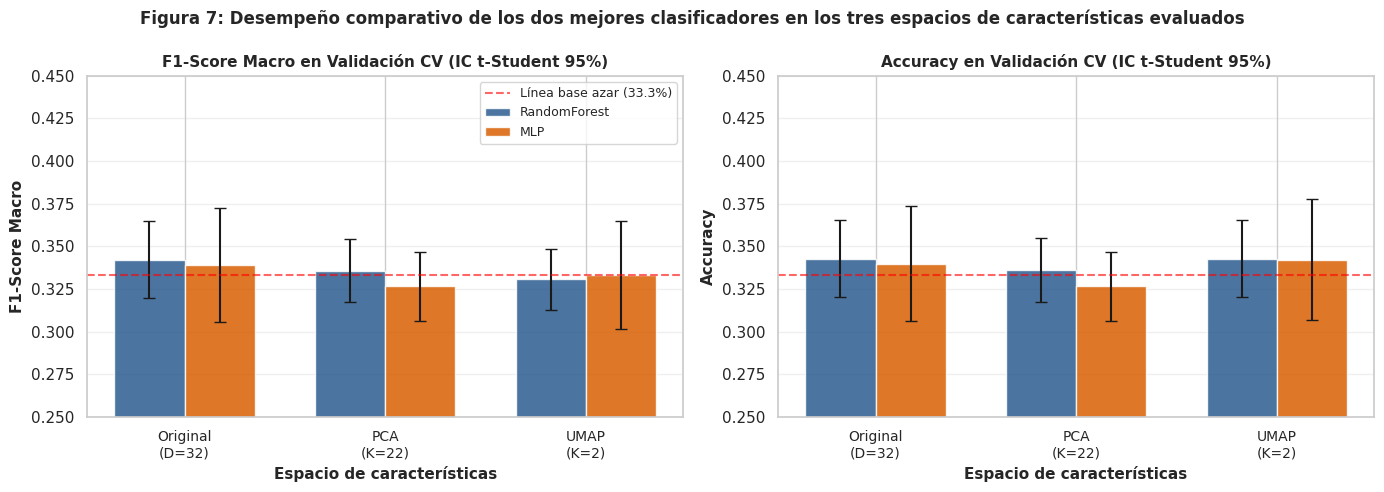

Figura 7 mostrada en el notebook.
Tabla 7: Síntesis integral de desempeño y compresión dimensional en todos los espacios de características


,Modelo,Espacio de Características,Dimensión,% Reducción,Train F1,Val F1-Macro,Test F1-Macro,Test Accuracy,Test Bal. Acc,Test ROC-AUC
0,RandomForest,Original (D=32),32,0.00%,1.0000,"0.3423 [0.3195, 0.3651]","0.3450 [0.3065, 0.3844]",0.3450,0.3450,0.5043
1,RandomForest,PCA (K=22),22,31.2%,1.0000,"0.3359 [0.3175, 0.3543]","0.3400 [0.3017, 0.3802]",0.3400,0.3400,0.4907
2,RandomForest,UMAP (K=2),2,93.8%,1.0000,"0.3308 [0.3128, 0.3487]","0.3171 [0.2816, 0.3529]",0.3167,0.3167,0.4714
3,MLP,Original (D=32),32,0.00%,1.0000,"0.3393 [0.3059, 0.3728]","0.3381 [0.3020, 0.3791]",0.3383,0.3383,0.5128
4,MLP,PCA (K=22),22,31.2%,0.9979,"0.3266 [0.3063, 0.3468]","0.3225 [0.2819, 0.3578]",0.3233,0.3233,0.4946
5,MLP,UMAP (K=2),2,93.8%,0.9971,"0.3333 [0.3014, 0.3651]","0.2525 [0.2209, 0.2856]",0.3217,0.3217,0.4965



=== Conclusiones Formales de la Evaluación Completa ===

Modelo: RandomForest
  • Comparación con el azar (1/3):
    - Espacio Original: IC [0.3195, 0.3651] → Solapa con 1/3 (señal tenue)
    - Espacio PCA     : IC [0.3175, 0.3543] → Solapa con 1/3
    - Espacio UMAP    : IC [0.3128, 0.3487] → Solapa con 1/3
  • Comparación de espacios (Solapamiento de IC):
    - Original vs PCA : Diferencia NO estadísticamente distinguible (IC solapan)
    - Original vs UMAP: Diferencia NO estadísticamente distinguible (IC solapan)

Modelo: MLP
  • Comparación con el azar (1/3):
    - Espacio Original: IC [0.3059, 0.3728] → Solapa con 1/3 (señal tenue)
    - Espacio PCA     : IC [0.3063, 0.3468] → Solapa con 1/3
    - Espacio UMAP    : IC [0.3014, 0.3651] → Solapa con 1/3
  • Comparación de espacios (Solapamiento de IC):
    - Original vs PCA : Diferencia NO estadísticamente distinguible (IC solapan)
    - Original vs UMAP: Diferencia NO estadísticamente distinguible (IC solapan)

• Compresión Dimens

In [33]:
# -----------------------------------------------------------------
# Generación de la Figura 7: Comparativa de los Dos Mejores Modelos en los 3 Espacios
# -----------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

spaces = [f'Original\n(D={D})', f'PCA\n(K={k_pca})', f'UMAP\n(K={k_umap_chosen})']
x_pos = np.arange(len(spaces))
w_bar = 0.35

for ax_idx, metric_key in enumerate(['f1_macro', 'accuracy']):
    metric_label = 'F1-Score Macro' if metric_key == 'f1_macro' else 'Accuracy'

    for m_idx, m_name in enumerate(top2_models):
        val_orig = experiment_log[m_name]['best_val'][metric_key]['mean']
        val_pca  = pca_test_models[m_name]['val'][metric_key]['mean']
        val_umap = umap_test_models[m_name]['val'][metric_key]['mean']

        err_orig = experiment_log[m_name]['best_val'][metric_key]['ci_high'] - val_orig
        err_pca  = pca_test_models[m_name]['val'][metric_key]['ci_high'] - val_pca
        err_umap = umap_test_models[m_name]['val'][metric_key]['ci_high'] - val_umap

        offset = -w_bar/2 if m_idx == 0 else w_bar/2
        color_b = '#2b5c8f' if m_idx == 0 else '#d95f02'

        axes[ax_idx].bar(x_pos + offset, [val_orig, val_pca, val_umap], w_bar,
                         yerr=[err_orig, err_pca, err_umap], capsize=4,
                         color=color_b, alpha=0.85, label=m_name if ax_idx == 0 else "")

    axes[ax_idx].axhline(y=1/3, color='red', linestyle='--', alpha=0.6, label='Línea base azar (33.3%)')
    axes[ax_idx].set_xticks(x_pos)
    axes[ax_idx].set_xticklabels(spaces, fontsize=10)
    axes[ax_idx].set_xlabel('Espacio de características', fontsize=11, fontweight='bold')
    axes[ax_idx].set_ylabel(metric_label, fontsize=11, fontweight='bold')
    axes[ax_idx].set_title(f'{metric_label} en Validación CV (IC t-Student 95%)', fontsize=11, fontweight='bold')
    axes[ax_idx].set_ylim(0.25, 0.45)
    axes[ax_idx].grid(True, alpha=0.3, axis='y')

axes[0].legend(fontsize=9, loc='upper right')
plt.suptitle('Figura 7: Desempeño comparativo de los dos mejores clasificadores en los tres espacios de características evaluados',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()
print("Figura 7 mostrada en el notebook.")

# -----------------------------------------------------------------
# Tabla Integral Generada Dinámicamente desde Variables
# -----------------------------------------------------------------
rows_integral = []

for m_name in top2_models:
    # 1. Original
    o_val = experiment_log[m_name]['best_val']['f1_macro']
    o_te = experiment_log[m_name]['test']
    o_ci = experiment_log[m_name]['test_ci']['f1_macro']
    rows_integral.append({
        'Modelo': m_name, 'Espacio de Características': f'Original (D={D})', 'Dimensión': D, '% Reducción': '0.00%',
        'Train F1': f"{experiment_log[m_name]['best_train']['f1_macro']['mean']:.4f}",
        'Val F1-Macro': f"{o_val['mean']:.4f} [{o_val['ci_low']:.4f}, {o_val['ci_high']:.4f}]",
        'Test F1-Macro': f"{o_te['f1_macro']:.4f} [{o_ci[0]:.4f}, {o_ci[1]:.4f}]",
        'Test Accuracy': f"{o_te['accuracy']:.4f}",
        'Test Bal. Acc': f"{o_te['balanced_accuracy']:.4f}",
        'Test ROC-AUC': f"{o_te['roc_auc_macro']:.4f}" if o_te['roc_auc_macro'] else "N/A"
    })

    # 2. PCA
    p_val = pca_test_models[m_name]['val']['f1_macro']
    p_te = pca_test_models[m_name]['test']
    p_ci = pca_test_models[m_name]['test_ci']['f1_macro']
    rows_integral.append({
        'Modelo': m_name, 'Espacio de Características': f'PCA (K={k_pca})', 'Dimensión': k_pca, '% Reducción': f"{pct_red_pca:.1f}%",
        'Train F1': f"{pca_test_models[m_name]['train']['f1_macro']['mean']:.4f}",
        'Val F1-Macro': f"{p_val['mean']:.4f} [{p_val['ci_low']:.4f}, {p_val['ci_high']:.4f}]",
        'Test F1-Macro': f"{p_te['f1_macro']:.4f} [{p_ci[0]:.4f}, {p_ci[1]:.4f}]",
        'Test Accuracy': f"{p_te['accuracy']:.4f}",
        'Test Bal. Acc': f"{p_te['balanced_accuracy']:.4f}",
        'Test ROC-AUC': f"{p_te['roc_auc_macro']:.4f}" if p_te['roc_auc_macro'] else "N/A"
    })

    # 3. UMAP
    u_val = umap_test_models[m_name]['val']['f1_macro']
    u_te = umap_test_models[m_name]['test']
    u_ci = umap_test_models[m_name]['test_ci']['f1_macro']
    rows_integral.append({
        'Modelo': m_name, 'Espacio de Características': f'UMAP (K={k_umap_chosen})', 'Dimensión': k_umap_chosen, '% Reducción': f"{pct_red_umap:.1f}%",
        'Train F1': f"{umap_test_models[m_name]['train']['f1_macro']['mean']:.4f}",
        'Val F1-Macro': f"{u_val['mean']:.4f} [{u_val['ci_low']:.4f}, {u_val['ci_high']:.4f}]",
        'Test F1-Macro': f"{u_te['f1_macro']:.4f} [{u_ci[0]:.4f}, {u_ci[1]:.4f}]",
        'Test Accuracy': f"{u_te['accuracy']:.4f}",
        'Test Bal. Acc': f"{u_te['balanced_accuracy']:.4f}",
        'Test ROC-AUC': f"{u_te['roc_auc_macro']:.4f}" if u_te['roc_auc_macro'] else "N/A"
    })

df_tabla7 = pd.DataFrame(rows_integral)

print("Tabla 7: Síntesis integral de desempeño y compresión dimensional en todos los espacios de características")
display(df_tabla7)

# -----------------------------------------------------------------
# Conclusiones Generadas Dinámicamente desde Variables (Sin números escritos a mano)
# -----------------------------------------------------------------
print("\n=== Conclusiones Formales de la Evaluación Completa ===")
overlaps_pca, overlaps_umap = {}, {}

for m_name in top2_models:
    o_val = experiment_log[m_name]['best_val']['f1_macro']
    p_val = pca_test_models[m_name]['val']['f1_macro']
    u_val = umap_test_models[m_name]['val']['f1_macro']

    # Comprobación (i): si IC incluye 1/3
    inc_rand_orig = (o_val['ci_low'] <= 1/3 <= o_val['ci_high'])
    inc_rand_pca  = (p_val['ci_low'] <= 1/3 <= p_val['ci_high'])
    inc_rand_umap = (u_val['ci_low'] <= 1/3 <= u_val['ci_high'])

    # Comprobación (ii): solapamiento entre Original y PCA / UMAP
    overlap_pca = not (o_val['ci_high'] < p_val['ci_low'] or p_val['ci_high'] < o_val['ci_low'])
    overlap_umap = not (o_val['ci_high'] < u_val['ci_low'] or u_val['ci_high'] < o_val['ci_low'])
    overlaps_pca[m_name] = overlap_pca
    overlaps_umap[m_name] = overlap_umap

    print(f"\nModelo: {m_name}")
    print(f"  • Comparación con el azar (1/3):")
    print(f"    - Espacio Original: IC [{o_val['ci_low']:.4f}, {o_val['ci_high']:.4f}] → {'Solapa con 1/3 (señal tenue)' if inc_rand_orig else 'Excluye 1/3 (señal significativa)'}")
    print(f"    - Espacio PCA     : IC [{p_val['ci_low']:.4f}, {p_val['ci_high']:.4f}] → {'Solapa con 1/3' if inc_rand_pca else 'Excluye 1/3'}")
    print(f"    - Espacio UMAP    : IC [{u_val['ci_low']:.4f}, {u_val['ci_high']:.4f}] → {'Solapa con 1/3' if inc_rand_umap else 'Excluye 1/3'}")
    print(f"  • Comparación de espacios (Solapamiento de IC):")
    print(f"    - Original vs PCA : {'Diferencia NO estadísticamente distinguible (IC solapan)' if overlap_pca else 'Diferencia distinguible'}")
    print(f"    - Original vs UMAP: {'Diferencia NO estadísticamente distinguible (IC solapan)' if overlap_umap else 'Diferencia distinguible'}")

print(f"\n• Compresión Dimensional:")
print(f"  - PCA logra una reducción del {pct_red_pca:.1f}% ({D} → {k_pca} componentes) preservando el 90% de la varianza explicada.")
print(f"  - UMAP logra una reducción del {pct_red_umap:.1f}% ({D} → {k_umap_chosen} componentes).")
for _nm, _ov, _pct, _dim in [('PCA', overlaps_pca, pct_red_pca, k_pca), ('UMAP', overlaps_umap, pct_red_umap, k_umap_chosen)]:
    if all(_ov.values()):
        print(f"  - Conclusión ({_nm}): los IC de validación de los dos modelos solapan con los del espacio original; se puede reducir la dimensionalidad un {_pct:.1f}% ({D} → {_dim}) sin pérdida estadísticamente distinguible.")
    else:
        _bad = [m for m, ov in _ov.items() if not ov]
        print(f"  - Conclusión ({_nm}): hay diferencia distinguible respecto al espacio original para {_bad}; la reducción del {_pct:.1f}% debe tomarse con cautela.")

print("\n• Recomendación final por parsimonia (menor dimensión cuyo F1 de validación cae dentro del IC 95% del mejor espacio):")
for m_name in top2_models:
    cand = {
        f'Original (D={D})': (D, experiment_log[m_name]['best_val']['f1_macro']),
        f'PCA (K={k_pca})': (k_pca, pca_test_models[m_name]['val']['f1_macro']),
        f'UMAP (K={k_umap_chosen})': (k_umap_chosen, umap_test_models[m_name]['val']['f1_macro']),
    }
    best_name = max(cand, key=lambda n: cand[n][1]['mean'])
    best_low = cand[best_name][1]['ci_low']
    adm = {n: v for n, v in cand.items() if v[1]['mean'] >= best_low}
    pick = min(adm, key=lambda n: adm[n][0])
    print(f"  - {m_name}: mejor F1 de validación en {best_name} ({cand[best_name][1]['mean']:.4f}); espacio recomendado = {pick} (dimensión {adm[pick][0]}).")

_sup = np.bincount(y_test, minlength=3)
print("\n• Nota aritmética de validación:")
if len(set(_sup.tolist())) == 1:
    print(f"  En prueba hay {_sup[0]} muestras por clase (N_test={_sup.sum()}), por lo que Accuracy y Balanced Accuracy coinciden aritméticamente;")
else:
    print(f"  Soporte por clase en prueba = {_sup.tolist()}; Accuracy y Balanced Accuracy pueden diferir ligeramente.")
print("  la distribución de predicciones por clase de la Figura 2 permite descartar colapsos hacia una clase dominante.")


### Conclusiones finales y alcance de la evaluación

- **Selección sin fuga hacia prueba.** Hiperparámetros, los dos mejores modelos, $K$ de PCA y $K$ de UMAP se eligieron únicamente con validación cruzada; el conjunto de prueba se usó solo para la evaluación final.
- **Gestión del balance.** Se diagnostica el balance con `diagnose_balance` (IR y proporciones) en el dataset, en train/test y en cada pliegue, y una regla automática (`BALANCE_STRATEGY`) activa `class_weight` o sobremuestreo solo dentro de `run_cv`. Como el dataset está balanceado, la estrategia es `none`; la prueba de estrés (Tabla 3B, Figura 3B) muestra el efecto de cada técnica con IR = 5.0.
- **Comparación entre espacios.** Las conclusiones sobre si PCA o UMAP degradan el desempeño se derivan del solapamiento de los IC al 95% de validación (salidas de la celda anterior, Tablas 5 a 7 y Figura 7), sin cifras escritas a mano.
- **Limitación estadística.** Con $K=5$ pliegues los IC con $t$ de Student son aproximados, porque los pliegues comparten datos de entrenamiento y no son independientes; los IC bootstrap en prueba cuantifican solo la variabilidad del conjunto de 600 muestras.
- **Alcance predictivo.** Los modelos usan únicamente variables antecedentes ($t=0$). Si los IC de validación solapan con el azar ($1/3$), la señal predictiva disponible antes de conocer pérdida y tiempo de resolución es débil, y este resultado debe reportarse como tal.
